# 门诊多窗口调度｜双智能体与 6×6、10×6 对照

在 Jupyter 中打开文件，点击 **Run All / 运行全部**。默认从头训练并验证 **6 人 × 6 类医疗活动**和**10 人 × 6 类医疗活动**，然后用独立病例比较规则、遗传算法与学习策略。代码、合成数据生成器及本次运行输出都在同一个文件里。

- **PPO 选患者和活动**。窗口等待信息进入图状态。初训后，让策略在自己生成的排程状态里试选多个动作，用统一的规则补完余下排程，并根据最终在院时间学习排序。
- **DDQN 分配窗口**。输入包含窗口占用给其他就绪任务带来的额外等待。默认只有 PPO 在验证集通过就绪顺序基线，才正式训练 DDQN。可显式打开诊断模式，查看未通过门槛时的 DDQN 结果。
- **计时口径**。训练耗时与单批排程耗时分开。同一批病例用于所有比较方法。遗传算法默认 20 个体、15 代，规则基线与遗传算法均复用相同排程约束。

两组保持活动种类、窗口配置、客流设定和评测预算一致，各自训练并在各自的独立留出集上评测。两组均走小图加速路径。切换为 `RUN_SCOPE = "all"` 可启用原来的多规模训练与 30、50、100 人迁移评测。此 Notebook 使用自建仿真病例和改进算法，结果应按本次实验的范围解释。论文 DOI 为 `10.1007/s10791-024-09474-1`。


In [1]:
import importlib.util
import subprocess
import sys
import os

# 在导入 NumPy 之前设置 BLAS 线程数，小矩阵推断通常用单线程更快。
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
required = ["numpy", "pandas", "matplotlib"]
missing = [p for p in required if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    print("已安装", ", ".join(missing))
else:
    print("NumPy、pandas 和 Matplotlib 已就绪。")
try:
    from threadpoolctl import threadpool_limits
    _blas_limit = threadpool_limits(limits=1, user_api="blas")
except ImportError:
    _blas_limit = None

NumPy、pandas 和 Matplotlib 已就绪。


## 1. 配置

`RUN_SCOPE = "small"` 同时跑 6×6 和 10×6。可改为 `"6x6"`、`"10x6"` 单跑一个规模，或改为 `"all"` 跑多规模。

默认的 `pilot` 是可从头运行的小规模训练。`paper_budget` 会把 PPO 训练轮数提高到 10,000，运行时间更长。改变配置会使用不同的检查点目录。原版 Notebook 的权重结构和本版不同。


In [2]:
RUN_SCOPE = "small"               # "small"（6×6 和 10×6）、"6x6"、"10x6" 或 "all"
RUN_PROFILE = "pilot"             # "pilot" 或 "paper_budget"
RUN_DDQN_DIAGNOSTIC = True         # PPO 未过门槛时，是否仍训练 DDQN 作诊断
PPO_ROUNDS = 180 if RUN_PROFILE == "pilot" else 10_000
DDQN_EPISODES = 300 if RUN_PROFILE == "pilot" else 3_000
VALIDATION_CASES = 45 if RUN_PROFILE == "pilot" else 100
VALIDATE_EVERY = 30 if RUN_PROFILE == "pilot" else 250
SAVE_EVERY = 30 if RUN_PROFILE == "pilot" else 100
POLICY_PASSES = 10
POLICY_CASES_PER_PASS = 36
PPO_GATE_MARGIN = 0.05           # 至少快 0.05 分钟／人，才正式进入 DDQN 阶段
GA_POPULATION, GA_GENERATIONS = 20, 15
TEST_REPEATS = 3 if RUN_SCOPE == "all" else 12
assert RUN_SCOPE in ("small", "6x6", "10x6", "all") and RUN_PROFILE in ("pilot", "paper_budget")

### 1.1 输入一批患者，定义什么叫可行排程

输入是一组任务。每项任务写明患者、项目、允许使用的窗口，以及在每个窗口的耗时。
`before` 填前置任务的编号，患者到达时间单独填。检查之间如果可以自由排序，就不给它们互相加前置关系。
例如有一个项目可用两个窗口：A 做 8 分钟，B 做 5 分钟。B 如果还要等 10 分钟，A 现在就空着，
那么「最早完成」会选 A，因为 8 分钟后能做完，B 要 15 分钟。

这里在同一批已知患者上做离线排程。先保证患者已到达、本人前一项和全部前置项目已结束，再找合格窗口的空档。
患者本人的项目按选定顺序排，但窗口可以使用前面尚未被占用的空档。
每个窗口保存一张按时间排序的日历。新项目从患者最早能开始的时刻向后找，放入第一个装得下的空档。
如果窗口原来安排 A→C，新项目 B 放在它们之间，图上的窗口顺序就更新为 A→B→C。
医生窗口、各项检查窗口分别建模，无转运时间，每项任务连续完成。


In [3]:
from dataclasses import dataclass, replace
from collections import defaultdict, deque
from bisect import bisect_right
from itertools import permutations, product
from pathlib import Path
import heapq
import json
import math
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

TIME_UNIT = 60.0

@dataclass(frozen=True)
class Task:
    patient: int
    kind: str
    before: tuple
    options: tuple  # ((窗口名, 服务分钟), ...)

@dataclass(frozen=True)
class Case:
    arrival: tuple
    tasks: tuple

@dataclass(frozen=True)
class Booking:
    task: int
    desk: str
    start: int
    end: int

class Problem:
    """验证并整理输入。每个策略获得同一个 Problem，排程状态独立。"""
    def __init__(self, case):
        self.case = case
        self.tasks = case.tasks
        self.n = len(case.tasks)
        p = len(case.arrival)
        if not p or not self.n or any(not isinstance(a, int) or a < 0 for a in case.arrival):
            raise ValueError("到达时间须是非负的整数分钟，患者和任务不能为空")
        self.succ = [[] for _ in self.tasks]
        self.by_patient = [[] for _ in case.arrival]
        self.lookup = []
        self.edges = set()
        for i, t in enumerate(self.tasks):
            if not 0 <= t.patient < p:
                raise ValueError(f"任务 {i} 的患者编号无效")
            if not t.options or len(dict(t.options)) != len(t.options) or any(
                not isinstance(d, str) or not d or not isinstance(v, int) or v <= 0
                for d, v in t.options
            ):
                raise ValueError(f"任务 {i} 的窗口或时长无效")
            if len(set(t.before)) != len(t.before):
                raise ValueError(f"任务 {i} 的前置任务重复")
            for pred in t.before:
                if not 0 <= pred < self.n or self.tasks[pred].patient != t.patient or pred == i:
                    raise ValueError(f"任务 {i} 的前置任务无效")
                self.succ[pred].append(i)
                self.edges.add((pred, i))
            self.by_patient[t.patient].append(i)
            self.lookup.append(dict(t.options))
        if any(not tasks for tasks in self.by_patient):
            raise ValueError("每个患者至少要有一个项目")
        indegree = [len(t.before) for t in self.tasks]
        self.ready = [i for i, d in enumerate(indegree) if d == 0]
        queue = deque(self.ready)
        order = []
        while queue:
            i = queue.popleft()
            order.append(i)
            for nxt in self.succ[i]:
                indegree[nxt] -= 1
                if indegree[nxt] == 0:
                    queue.append(nxt)
        if len(order) != self.n:
            raise ValueError("前置关系有环")
        self.by_patient = [[] for _ in case.arrival]
        for i in order:
            self.by_patient[self.tasks[i].patient].append(i)
        self.minimum = [min(d.values()) for d in self.lookup]
        self.desks = sorted({desk for d in self.lookup for desk in d})
        self.tasks_by_desk = {desk: set() for desk in self.desks}
        for task, options in enumerate(self.lookup):
            for desk in options:
                self.tasks_by_desk[desk].add(task)
        self.width = max(map(len, self.lookup))
        self.work = [sum(self.minimum[i] for i in ids) for ids in self.by_patient]

class Schedule:
    def __init__(self, problem, graph=False):
        self.p = problem
        self.rows = []
        self.patient_end = list(problem.case.arrival)
        self.calendar = {desk: [] for desk in problem.desks}
        self.ends = [-1] * problem.n
        self.todo = [len(t.before) for t in problem.tasks]
        self.ready = set(problem.ready)
        self.work = problem.work.copy()
        self.left = list(map(len, problem.by_patient))
        self.graph = graph
        if graph:
            # 一条边可以同时来自固定约束、患者顺序和窗口顺序。
            self.edges = dict.fromkeys(sorted(problem.edges), 1)
            self.last_patient = {}
            self.features = np.zeros((problem.n, 2), np.float32)
            self.clb = [0] * problem.n
            for patient in range(len(self.patient_end)):
                self.update_nodes(patient)

    def update_nodes(self, patient):
        for i in self.p.by_patient[patient]:
            t = self.p.tasks[i]
            done = self.ends[i] >= 0
            self.clb[i] = self.ends[i] if done else max(
                self.patient_end[patient], max((self.clb[j] for j in t.before), default=0)
            ) + self.p.minimum[i]
            self.features[i] = (float(done), self.clb[i] / TIME_UNIT)

    def link(self, edge):
        self.edges[edge] = self.edges.get(edge, 0) + 1

    def unlink(self, edge):
        self.edges[edge] -= 1
        if self.edges[edge] == 0:
            del self.edges[edge]

    def node_state(self, observation="paper"):
        edges = np.asarray(tuple(self.edges), dtype=np.intp).reshape(-1, 2)
        legal = np.array(sorted(self.ready), dtype=np.intp)
        if observation == "paper":
            return self.features.copy(), edges, legal
        # 扩展对照：就绪时间 + 合格窗口造成的最短开工等待。
        extra = np.zeros_like(self.features)
        for i in legal:
            patient = self.p.tasks[i].patient
            ready = self.patient_end[patient]
            start = min(self.first_gap(desk, ready, duration)[1]
                        for desk, duration in self.p.tasks[i].options)
            extra[i] = ready / TIME_UNIT, (start-ready) / TIME_UNIT
        return np.concatenate((self.features, extra), axis=1), edges, legal

    def first_gap(self, desk, ready, duration):
        """返回第一个可行空档的插入位置和开工分钟，预订区间采用 [开始, 结束)。"""
        return self.gap_in(self.calendar[desk], ready, duration)

    @staticmethod
    def gap_in(booked, ready, duration):
        pos = bisect_right(booked, (ready, math.inf, math.inf))
        start = max(ready, booked[pos-1][1]) if pos else ready
        while pos < len(booked) and start + duration > booked[pos][0]:
            start = max(start, booked[pos][1])
            pos += 1
        return pos, start

    def window_state(self, task):
        patient = self.p.tasks[task].patient
        ready = self.patient_end[patient]
        options = self.p.tasks[task].options
        x = np.zeros((self.p.width, 3), np.float32)
        for idx, (desk, duration) in enumerate(options):
            pos, start = self.first_gap(desk, ready, duration)
            end = start + duration
            pressure = 0
            if len(options) > 1:
                calendar = self.calendar[desk]
                shadow = calendar[:pos] + [(start, end, task)] + calendar[pos:]
                for other in sorted(self.ready & self.p.tasks_by_desk[desk]):
                    other_patient = self.p.tasks[other].patient
                    if other_patient == patient:
                        continue
                    other_ready = self.patient_end[other_patient]
                    other_duration = self.p.lookup[other][desk]
                    _, old_start = self.first_gap(desk, other_ready, other_duration)
                    old_end = old_start + other_duration
                    if old_end <= start or old_start >= end:
                        continue
                    alternatives = [self.first_gap(d, other_ready, length)[1] + length
                                    for d, length in self.p.tasks[other].options if d != desk]
                    best_alt = min(alternatives, default=math.inf)
                    if best_alt <= old_end:
                        continue
                    new_end = self.gap_in(shadow, other_ready, other_duration)[1] + other_duration
                    pressure += min(best_alt, new_end) - old_end
            x[idx] = ((start-ready)/TIME_UNIT, (end-ready)/TIME_UNIT, pressure/TIME_UNIT)
        return x, len(options)

    def earliest(self, task):
        free = self.patient_end[self.p.tasks[task].patient]
        return min(self.p.tasks[task].options, key=lambda option:
                   (self.first_gap(option[0], free, option[1])[1] + option[1], option[0]))[0]

    def place(self, i, desk):
        if i not in self.ready or desk not in self.p.lookup[i]:
            raise ValueError("该项目暂不可排，或所选窗口无资格")
        patient = self.p.tasks[i].patient
        old_end = self.patient_end[patient]
        duration = self.p.lookup[i][desk]
        position, start = self.first_gap(desk, old_end, duration)
        end = start + duration
        bookings = self.calendar[desk]
        previous = bookings[position-1][2] if position else None
        following = bookings[position][2] if position < len(bookings) else None
        bookings.insert(position, (start, end, i))
        self.rows.append(Booking(i, desk, start, end))
        self.ends[i] = end
        self.patient_end[patient] = end
        self.ready.remove(i)
        self.work[patient] -= self.p.minimum[i]
        self.left[patient] -= 1
        for nxt in self.p.succ[i]:
            self.todo[nxt] -= 1
            if self.todo[nxt] == 0:
                self.ready.add(nxt)
        if self.graph:
            if patient in self.last_patient:
                self.link((self.last_patient[patient], i))
            if previous is not None and following is not None:
                self.unlink((previous, following))
            if previous is not None:
                self.link((previous, i))
            if following is not None:
                self.link((i, following))
            self.last_patient[patient] = i
            self.update_nodes(patient)
        # 变化只来自这个患者。潜势是已排到的末尾 + 剩余最短耗时 - 到达时间。
        return (old_end - end + self.p.minimum[i]) / TIME_UNIT

## 2. 独立审计排程，计算可比较的业务指标

检查器只看原始输入和最终排程，和排程器各算各的。
总在院时长 = 每位患者（末项完成时间 − 到达时间）再求和，是论文优化目标。
患者等待 = 在院时长 − 各项实际服务分钟，包含首项前等待和项目间等待。
P90 取本批患者等待的 90% 分位数。对照时计时仅涵盖策略生成方案，审计、训练、画图不算在里面。


In [4]:
def audit(p, rows):
    errors, by_task = set(), {}
    desk_rows, patient_rows = defaultdict(list), defaultdict(list)
    for b in rows:
        if not 0 <= b.task < p.n:
            errors.add("未知任务")
            continue
        t = p.tasks[b.task]
        if b.task in by_task:
            errors.add("任务重复")
        by_task[b.task] = b
        if b.desk not in p.lookup[b.task]:
            errors.add("窗口无资格")
        if b.start >= b.end or b.end - b.start != p.lookup[b.task].get(b.desk):
            errors.add("时长错误")
        if b.start < p.case.arrival[t.patient]:
            errors.add("到达前开工")
        desk_rows[b.desk].append(b)
        patient_rows[t.patient].append(b)
    if len(by_task) != p.n:
        errors.add("任务漏排")
    for i, b in by_task.items():
        if any(k not in by_task or by_task[k].end > b.start for k in p.tasks[i].before):
            errors.add("前置未完成")
    for label, groups in (("窗口撞单", desk_rows), ("患者撞单", patient_rows)):
        for bookings in groups.values():
            end = -math.inf
            for b in sorted(bookings, key=lambda x: x.start):
                if b.start < end:
                    errors.add(label)
                end = max(end, b.end)
    return sorted(errors)

def measures(p, rows):
    errors = audit(p, rows)
    if errors:
        return dict(feasible=False, total_flow=np.nan, mean_flow=np.nan, p90_wait=np.nan)
    finish = [0] * len(p.case.arrival)
    service = finish.copy()
    for b in rows:
        j = p.tasks[b.task].patient
        finish[j] = max(finish[j], b.end)
        service[j] += b.end - b.start
    flow = np.subtract(finish, p.case.arrival)
    wait = flow - service
    return dict(feasible=True, total_flow=int(flow.sum()), mean_flow=float(flow.mean()),
                p90_wait=float(np.quantile(wait, 0.9)))

def schedule_frame(p, rows):
    return pd.DataFrame([
        (b.task, p.tasks[b.task].patient + 1, p.tasks[b.task].kind, b.desk, b.start, b.end)
        for b in sorted(rows, key=lambda row: (row.start, row.desk))
    ], columns=["Task", "Patient", "Activity", "Desk", "Start (min)", "End (min)"])

def queue_metrics(p, rows):
    """按患者拆等待；复诊窗口空着且有人已就绪时，累计窗口分钟。"""
    by_task = {b.task: b for b in rows}
    follow_events = defaultdict(lambda: defaultdict(lambda: [0, 0]))
    waits = defaultdict(int)
    for patient, ids in enumerate(p.by_patient):
        ready = p.case.arrival[patient]
        for b in sorted((by_task[i] for i in ids), key=lambda b: b.start):
            kind = p.tasks[b.task].kind
            waits[kind] += b.start-ready
            if kind == "Follow" and len(p.tasks[b.task].options) == 1 and ready < b.start:
                follow_events[b.desk][ready][0] += 1
                follow_events[b.desk][b.start][0] -= 1
            ready = b.end
    for b in rows:
        if b.desk in follow_events:
            follow_events[b.desk][b.start][1] += 1
            follow_events[b.desk][b.end][1] -= 1
    idle = 0
    for timeline in follow_events.values():
        waiting, busy, last = 0, 0, 0
        for minute, (delta_wait, delta_busy) in sorted(timeline.items()):
            if waiting > 0 and busy == 0:
                idle += minute-last
            waiting += delta_wait
            busy += delta_busy
            last = minute
    n = len(p.case.arrival)
    return dict(consult_wait=waits["Consult"]/n, follow_wait=waits["Follow"]/n,
                follow_idle_with_waiting=idle)

## 3. 从论文表 4 验算

三位患者都要做 CT、血常规 CBC、心电图 ECG。用论文给出的九个时长，
本例设三位患者均在 0 分钟到达、每项检查一个窗口。论文图 3 展示可行解；
这里另外枚举三个患者和三个窗口各自可能的顺序，独立求出该设定下的精确最优值。
如果一组顺序互相矛盾就会出现环，直接淘汰。剩余顺序按前置关系推算最早开工。


In [5]:
names = ("CT", "CBC", "ECG")
durations = ((2, 7, 2), (4, 4, 1), (7, 4, 6))
toy = Problem(Case((0, 0, 0), tuple(
    Task(j, name, (), ((name, durations[j][i]),))
    for j in range(3) for i, name in enumerate(names)
)))

def exact_table4(p):
    groups = [list(range(3*j, 3*j+3)) for j in range(3)]
    groups += [list(range(i, 9, 3)) for i in range(3)]
    best, best_order, tested, feasible = math.inf, None, 0, 0
    for orders in product(*(list(permutations(g)) for g in groups)):
        tested += 1
        succ, indeg = [[] for _ in range(9)], [0]*9
        for a, b, c in orders:
            succ[a].append(b)
            succ[b].append(c)
            indeg[b] += 1
            indeg[c] += 1
        queue = [i for i in range(9) if indeg[i] == 0]
        starts = [0]*9
        for i in queue:
            finish = starts[i] + p.minimum[i]
            for j in succ[i]:
                starts[j] = max(starts[j], finish)
                indeg[j] -= 1
                if indeg[j] == 0:
                    queue.append(j)
        if len(queue) != 9:
            continue
        feasible += 1
        score = sum(max(starts[i] + p.minimum[i] for i in group) for group in groups[:3])
        if score < best:
            best, best_order = score, queue.copy()
    env = Schedule(p)
    for i in best_order:
        env.place(i, p.tasks[i].kind)
    return tested, feasible, best, env.rows

tested, feasible, optimum, exact = exact_table4(toy)
assert (tested, feasible, optimum) == (46656, 19164, 39)
assert measures(toy, exact)["total_flow"] == optimum
print(f"枚举 {tested:,} 种顺序，可行 {feasible:,} 种。最优总在院时长 {optimum} 患者·分钟。")
display(schedule_frame(toy, exact))

audit_case = Problem(Case((0, 0), (
    Task(0, "reg", (), (("R", 2),)), Task(0, "exam", (0,), (("X", 3),)),
    Task(1, "exam", (), (("X", 3),)),
)))
valid = [Booking(0, "R", 0, 2), Booking(1, "X", 2, 5), Booking(2, "X", 5, 8)]
faults = {
    "有效排程": (valid, set()),
    "同一个患者做两项 / 前置未完成": ([valid[0], Booking(1, "X", 1, 4), valid[2]],
                                     {"患者撞单", "前置未完成"}),
    "同一个窗口做两项": ([*valid[:2], Booking(2, "X", 3, 6)], {"窗口撞单"}),
    "窗口没资格": ([replace(valid[0], desk="Z"), *valid[1:]], {"窗口无资格", "时长错误"}),
    "漏排": (valid[:2], {"任务漏排"}),
}
for label, (rows, expected) in faults.items():
    got = audit(audit_case, rows)
    assert set(got) == expected, (label, got, expected)
    print(f"{label} → {', '.join(got) if got else '通过'}")

# 先锁定 [0, 10) 和 [30, 40)，再提交第三个项目，预期插入中间。
gap_case = Problem(Case((0, 30, 12), tuple(
    Task(i, "CT", (), (("CT/1", length),)) for i, length in enumerate((10, 10, 8))
)))
gap = Schedule(gap_case, graph=True)
for task in (0, 1, 2):
    gap.place(task, "CT/1")
assert gap.rows[-1] == Booking(2, "CT/1", 12, 20)
assert set(gap.edges) == {(0, 2), (2, 1)} and not audit(gap_case, gap.rows)
print("插空验算：第三个项目排在 12–20 分钟，窗口边从 0→1 更新为 0→2→1。")

枚举 46,656 种顺序，可行 19,164 种。最优总在院时长 39 患者·分钟。
有效排程 → 通过
同一个患者做两项 / 前置未完成 → 前置未完成, 患者撞单
同一个窗口做两项 → 窗口撞单
窗口没资格 → 时长错误, 窗口无资格
漏排 → 任务漏排
插空验算：第三个项目排在 12–20 分钟，窗口边从 0→1 更新为 0→2→1。


,Task,Patient,Activity,Desk,Start (min),End (min)
0,4,2,CBC,CBC,0,4
1,2,1,ECG,ECG,0,2
2,0,1,CT,CT,2,4
3,8,3,ECG,ECG,2,8
4,1,1,CBC,CBC,4,11
5,3,2,CT,CT,4,8
6,6,3,CT,CT,8,15
7,5,2,ECG,ECG,8,9
8,7,3,CBC,CBC,15,19


## 4. 合成病例与对照策略

对照规则包括 READY、SPT、MWKR、MOPNR。READY 按当前活动的就绪时间排序，SPT 优先耗时短的项目，MWKR 优先剩余工作量大的患者，MOPNR 优先剩余项目多的患者。规则统一采用最早完工分台。遗传算法以这四条规则的可行排程初始化搜索。

病例生成器覆盖不同患者数、医疗活动种类、窗口配置与客流条件。初诊及复诊各一个窗口，挂号、检查和取药可配置 1–3 个候选窗口。


In [6]:
LOADS = ("low", "near_capacity", "peak")

def arrival_times(n, mean_consult, rng, load):
    nominal = {"low": .65, "near_capacity": .95, "peak": .80}[load]
    gaps = rng.gamma(4, .25, n-1)
    targets = np.full(n-1, mean_consult / nominal)
    if load == "peak":
        targets[:max(1, (n-1)//3)] = mean_consult / 2.0
    return tuple(map(int, np.rint(np.r_[0, (gaps*targets).cumsum()])))

def synthetic(n, m, k, seed, load="near_capacity"):
    if n < 1 or m < 5 or not 1 <= k <= 3:
        raise ValueError("需要至少一位患者、五类项目、1–3 个可变窗口")
    parts = np.random.SeedSequence(seed).spawn(3)
    rng, service_rng, arrival_rng = map(np.random.default_rng, parts)
    exams = [f"Exam-{i+1:02}" for i in range(m-4)]
    base = {"Reg": 4, "Consult": 10, "Follow": 7, "Rx": 4}
    base.update(zip(exams, map(int, rng.integers(7, 22, len(exams)))))
    pace = {a: service_rng.uniform(.82, 1.18, 1 if a in ("Consult", "Follow") else 3)
            for a in base}
    tasks = []
    def add(patient, kind, predecessors):
        idx = len(tasks)
        length = base[kind] * rng.uniform(.70, 1.32)
        options = tuple((f"{kind}/{d+1}", max(1, round(length*f + service_rng.uniform(-2, 2))))
                        for d, f in enumerate(pace[kind]))
        tasks.append(Task(patient, kind, predecessors, options[:k]))
        return idx
    for j in range(n):
        reg = add(j, "Reg", ())
        consult = add(j, "Consult", (reg,))
        count = rng.integers(min(2, len(exams)), min(5, len(exams)) + 1)
        selected = sorted(rng.choice(exams, count, replace=False))
        exams_done = tuple(add(j, e, (consult,)) for e in selected)
        follow = add(j, "Follow", exams_done)
        add(j, "Rx", (follow,))
    mean_consult = np.mean([t.options[0][1] for t in tasks if t.kind == "Consult"])
    return Problem(Case(arrival_times(n, mean_consult, arrival_rng, load), tuple(tasks)))

def rule(p, mode):
    env = Schedule(p)
    while env.ready:
        def rank(i):
            j = p.tasks[i].patient
            if mode == "READY":
                return (env.patient_end[j], p.case.arrival[j], i)
            if mode == "SPT":
                return (p.minimum[i], env.patient_end[j], i)
            if mode == "MWKR":
                return (-env.work[j], env.patient_end[j], i)
            if mode == "MOPNR":
                return (-env.left[j], env.patient_end[j], i)
            raise ValueError(mode)
        i = min(env.ready, key=rank)
        env.place(i, env.earliest(i))
    return env.rows

def genetic(p, seed, population=12, generations=10):
    if population < 6:
        raise ValueError("种群至少要容纳四个规则种子和随机个体")
    rng = np.random.default_rng(seed)
    option_counts = np.asarray([len(t.options) for t in p.tasks])
    def decode(gene):
        env = Schedule(p)
        # 固定基因优先级可用堆保存，只把已经就绪的项目推入堆。
        priority = gene[0].tolist()
        slots = np.floor(gene[1] * option_counts).astype(int)
        queue = [(priority[i], i) for i in p.ready]
        heapq.heapify(queue)
        while queue:
            _, i = heapq.heappop(queue)
            env.place(i, p.tasks[i].options[slots[i]][0])
            for j in p.succ[i]:
                if env.todo[j] == 0:
                    heapq.heappush(queue, (priority[j], j))
        return sum(e-a for e, a in zip(env.patient_end, p.case.arrival)), env.rows
    genes = rng.random((population, 2, p.n))
    for g, method in enumerate(("READY", "SPT", "MWKR", "MOPNR")):
        for rank, booking in enumerate(rule(p, method)):
            opts = list(p.lookup[booking.task])
            genes[g, :, booking.task] = (rank/p.n, (opts.index(booking.desk)+.5)/len(opts))
    scores = [decode(g) for g in genes]
    for _ in range(generations):
        ranked = sorted(range(population), key=lambda i: scores[i][0])
        next_genes = [genes[i] for i in ranked[:2]]
        next_scores = [scores[i] for i in ranked[:2]]
        while len(next_genes) < population:
            a, b = rng.choice(ranked[:population//2], 2, replace=False)
            child = np.where(rng.random((2, p.n)) < .5, genes[a], genes[b])
            change = rng.random((2, p.n)) < .07
            child[change] = rng.random(change.sum())
            next_genes.append(child)
            next_scores.append(decode(child))
        genes, scores = np.asarray(next_genes), next_scores
    return min(scores, key=lambda result: result[0])[1]


for method in ("READY", "SPT", "MWKR", "MOPNR", "GA"):
    rows = genetic(toy, 100) if method == "GA" else rule(toy, method)
    result = measures(toy, rows)
    assert result["feasible"] and result["total_flow"] >= optimum
    print(f"{method:5s} → 总在院 {result['total_flow']} 患者·分钟")

paired_low = synthetic(15, 10, 1, 600, "low")
paired_peak = synthetic(15, 10, 3, 600, "peak")
assert all(a == replace(b, options=b.options[:1]) for a, b in zip(paired_low.tasks, paired_peak.tasks))
assert paired_low.case.arrival != paired_peak.case.arrival
print("病例生成检查通过：改变客流和窗口数，患者项目、前置关系和第一个窗口的时长一致。")

READY → 总在院 48 患者·分钟
SPT   → 总在院 44 患者·分钟
MWKR  → 总在院 60 患者·分钟
MOPNR → 总在院 48 患者·分钟
GA    → 总在院 39 患者·分钟
病例生成检查通过：改变客流和窗口数，患者项目、前置关系和第一个窗口的时长一致。


## 5. 双智能体与快速排程

PPO 看图和窗口等待信息，DDQN 在合格窗口中选台。选好后更新同一个排程。若只有一个合法选项，直接采用。DDQN 的占用代价来自一次临时插入，度量该窗口对其他已就绪任务最早完工的影响。单窗口病例没有分台选择。

小图使用增量邻接矩阵、等待缓存和批量更新。其他图沿用边列表。出现近似并列时，小图推理用原打分路径复核，避免因浮点误差而改选。批量更新与逐条更新的浮点累加顺序可能不同。


In [7]:
def linear(rng, n_in, n_out, scale=1.0):
    return [rng.normal(0, scale/np.sqrt(n_in), (n_in, n_out)).astype(np.float32),
            np.zeros(n_out, np.float32)]

def affine(x, parameters):
    w, b = parameters
    return x @ w + b

def mlp(x, parameters, activation=True):
    hidden = np.tanh(affine(x, parameters[:2]))
    raw = affine(hidden, parameters[2:])
    y = np.tanh(raw) if activation else raw
    return y, (x, hidden, y, activation)

def mlp_back(dy, cache, parameters):
    x, hidden, y, activated = cache
    dz = dy * (1-y*y) if activated else dy
    w1, _, w2, _ = parameters
    dh = (dz @ w2.T) * (1-hidden*hidden)
    return dh @ w1.T, [x.T @ dh, dh.sum(0), hidden.T @ dz, dz.sum(0)]

def save_weights(path, parameters):
    np.savez_compressed(path, *parameters)

def load_weights(path, parameters):
    with np.load(path) as file:
        assert len(file.files) == len(parameters)
        for i, value in enumerate(parameters):
            array = file[f"arr_{i}"]
            assert value.shape == array.shape and np.isfinite(array).all()
            value[...] = array

class Adam:
    def __init__(self, parameters, lr):
        self.parameters = parameters
        self.lr, self.t = lr, 0
        self.m = [np.zeros_like(w) for w in parameters]
        self.v = [np.zeros_like(w) for w in parameters]

    def step(self, gradients):
        norm = math.sqrt(sum(float(np.square(g).sum()) for g in gradients))
        scale = min(1.0, 0.5/(norm + 1e-9))
        self.t += 1
        for w, m, v, g in zip(self.parameters, self.m, self.v, gradients):
            g = g * scale
            m *= .9
            m += .1*g
            v *= .999
            v += .001*g*g
            w -= self.lr * (m/(1-.9**self.t)) / (np.sqrt(v/(1-.999**self.t)) + 1e-8)

def aggregate(x, edges, reverse=False):
    src, dst = edges.T
    if reverse:
        src, dst = dst, src
    out = x.copy()
    np.add.at(out, dst, x[src])
    return out

class PPO:
    def __init__(self, seed, observation="paper"):
        if observation not in ("paper", "window_aware"):
            raise ValueError(observation)
        self.observation = observation
        rng = np.random.default_rng(seed)
        self.g1 = linear(rng, 2 if observation == "paper" else 4, 64) + linear(rng, 64, 64)
        self.g2 = linear(rng, 64, 64) + linear(rng, 64, 64)
        self.actor = linear(rng, 128, 32) + linear(rng, 32, 1, .05)
        self.critic = linear(rng, 64, 32) + linear(rng, 32, 1, .1)
        self.parameters = self.g1 + self.g2 + self.actor + self.critic

    def forward(self, state):
        x, edges, legal = state
        h1, c1 = mlp(aggregate(x, edges), self.g1)
        h2, c2 = mlp(aggregate(h1, edges), self.g2)
        pool = h2.mean(axis=0, keepdims=True)
        local = np.concatenate((h2[legal], np.broadcast_to(pool, (len(legal), 64))), axis=1)
        logits, ca = mlp(local, self.actor, activation=False)
        value, cv = mlp(pool, self.critic, activation=False)
        z = logits[:, 0] - logits.max()
        prob = np.exp(z)
        prob /= prob.sum()
        return prob, float(value.item()), (edges, legal, c1, c2, ca, cv, len(x))

    def choose(self, state):
        x, edges, legal = state
        if len(legal) == 1:
            return int(legal[0])
        h = np.tanh(affine(np.tanh(affine(aggregate(x, edges), self.g1[:2])), self.g1[2:]))
        h = np.tanh(affine(np.tanh(affine(aggregate(h, edges), self.g2[:2])), self.g2[2:]))
        pooled = h.mean(axis=0)
        # Same affine map, split at the local/global concatenation.
        w, b, v, c = self.actor
        hidden = np.tanh(h[legal] @ w[:64] + pooled @ w[64:] + b)
        return int(legal[np.argmax(hidden @ v + c)])

    def backward(self, logits_grad, value_grad, cache):
        edges, legal, c1, c2, ca, cv, n = cache
        da, ga = mlp_back(logits_grad[:, None], ca, self.actor)
        dv, gv = mlp_back(np.asarray([[value_grad]], np.float32), cv, self.critic)
        dh = np.broadcast_to((da[:, 64:].sum(0) + dv[0]) / n, (n, 64)).copy()
        dh[legal] += da[:, :64]
        dh1, g2 = mlp_back(dh, c2, self.g2)
        _, g1 = mlp_back(aggregate(dh1, edges, reverse=True), c1, self.g1)
        return g1 + g2 + ga + gv

class DDQN:
    def __init__(self, seed):
        rng = np.random.default_rng(seed)
        self.parameters = linear(rng, 6, 32) + linear(rng, 32, 1, .1)

    def forward(self, x, mask):
        # 共享打分器使 1、2、3 个候选窗口可用同一套权重。
        mean = (x * mask[..., None]).sum(-2, keepdims=True) / mask.sum(-1)[..., None, None]
        features = np.concatenate([x, np.broadcast_to(mean, x.shape)], axis=-1)
        values, cache = mlp(features.reshape(-1, 6).astype(np.float32),
                            self.parameters, activation=False)
        return values.reshape(mask.shape), cache

    def choose(self, state):
        x, count = state
        mask = np.arange(len(x)) < count
        q, _ = self.forward(x, mask)
        return int(np.argmax(q[:count]))

def learned(p, agent, window=None):
    env = Schedule(p, graph=True)
    while env.ready:
        task = next(iter(env.ready)) if len(env.ready) == 1 else agent.choose(env.node_state(agent.observation))
        options = p.tasks[task].options
        if len(options) == 1:
            desk = options[0][0]
        elif window is None:
            desk = env.earliest(task)
        elif window == "pressure_tie":
            features, count = env.window_state(task)
            best = min(range(count), key=lambda i: (features[i,1], features[i,2], options[i][0]))
            desk = options[best][0]
        else:
            desk = options[window.choose(env.window_state(task))][0]
        env.place(task, desk)
    return env.rows

In [8]:
class FastSchedule(Schedule):
    """Dense adjacency for a small graph, maintained as its edges change."""
    def __init__(self,p,graph=False):
        super().__init__(p,graph)
        self.dense = graph and p.n <= 64
        if self.dense:
            self.adj=np.eye(p.n,dtype=np.float32)
            self.wait_cache={}
            for src,dst in self.edges:
                self.adj[dst,src]=1

    def link(self,edge):
        super().link(edge)
        src,dst=edge
        if self.dense:
            self.adj[dst,src]=1

    def unlink(self,edge):
        super().unlink(edge)
        if self.dense and edge not in self.edges:
            src,dst=edge
            self.adj[dst,src]=0

    def node_state(self,observation="paper",snapshot=True):
        if not self.dense:
            return super().node_state(observation)
        legal=np.asarray(sorted(self.ready),dtype=np.intp)
        if observation=="paper":
            features=self.features.copy() if snapshot else self.features
        else:
            features=np.zeros((self.p.n,4),np.float32)
            features[:,:2]=self.features
            for i in legal:
                t=self.p.tasks[i]
                ready=self.patient_end[t.patient]
                if i not in self.wait_cache:
                    start=min(self.first_gap(d,ready,length)[1] for d,length in t.options)
                    self.wait_cache[i]=start-ready
                features[i,2:]=(ready/TIME_UNIT,self.wait_cache[i]/TIME_UNIT)
        return features,self.adj.copy() if snapshot else self.adj,legal

    def place(self,task,desk):
        reward=super().place(task,desk)
        if self.dense:
            self.wait_cache.pop(task,None)
            patient=self.p.tasks[task].patient
            changed=self.p.tasks_by_desk[desk].intersection(self.ready)
            changed.update(self.p.by_patient[patient])
            for i in changed:
                self.wait_cache.pop(i,None)
        return reward

    def window_state(self,task):
        x,count=super().window_state(task)
        if len(x)<3:
            fixed=np.zeros((3,3),dtype=x.dtype)
            fixed[:len(x)]=x
            x=fixed
        return x,count


class FastPPO(PPO):
    def forward(self,state):
        x,adj,legal=state
        if adj.dtype.kind in "iu":
            prob,value,cache=super().forward(state)
            return prob,value,("sparse",cache)
        h1,c1=mlp(adj@x,self.g1)
        h2,c2=mlp(adj@h1,self.g2)
        pool=h2.mean(axis=0,keepdims=True)
        local=np.concatenate((h2[legal],np.broadcast_to(pool,(len(legal),64))),axis=1)
        logits,ca=mlp(local,self.actor,activation=False)
        value,cv=mlp(pool,self.critic,activation=False)
        prob=np.exp(logits[:,0]-logits.max())
        prob/=prob.sum()
        return prob,float(value.item()),(adj,legal,c1,c2,ca,cv,len(x))

    def choose(self,state,original_edges=None):
        x,adj,legal=state
        if adj.dtype.kind in "iu":
            return super().choose(state)
        if len(legal)==1:
            return int(legal[0])
        h1,_=mlp(adj@x,self.g1)
        h2,_=mlp(adj@h1,self.g2)
        w,b,v,c=self.actor
        hidden=np.tanh(h2[legal]@w[:64]+h2.mean(axis=0)@w[64:]+b)
        score=(hidden@v+c)[:,0]
        best=int(np.argmax(score))
        if original_edges is not None and np.count_nonzero(score[best]-score<=1e-6)>1:
            return super().choose((x,original_edges(),legal))
        return int(legal[best])

    def backward(self,logits_grad,value_grad,cache):
        if len(cache)==2:
            return super().backward(logits_grad,value_grad,cache[1])
        adj,legal,c1,c2,ca,cv,n=cache
        da,ga=mlp_back(logits_grad[:,None],ca,self.actor)
        dv,gv=mlp_back(np.asarray([[value_grad]],np.float32),cv,self.critic)
        dh=np.broadcast_to((da[:,64:].sum(0)+dv[0])/n,(n,64)).copy()
        dh[legal]+=da[:,:64]
        dh1,g2=mlp_back(dh,c2,self.g2)
        _,g1=mlp_back(adj.T@dh1,c1,self.g1)
        return g1+g2+ga+gv


class FastDDQN(DDQN):
    def choose(self,state):
        x,count=state
        if count==1:
            return 0
        active=x[:count]
        mean=(active.sum(axis=0)/float(count)).astype(np.float32)
        w,b,v,c=self.parameters
        h=np.tanh(active@w[:3]+mean@w[3:]+b)
        score=(h@v+c)[:,0]
        best=int(np.argmax(score))
        # Preserve the old decision for ties and floating-point near ties.
        if np.count_nonzero(score[best]-score<=1e-6)>1:
            return super().choose(state)
        return best


class Replay:
    def __init__(self,capacity):
        self.capacity=capacity
        self.size=0
        self.head=0
        self.arrays=(np.empty((capacity,3,3),np.float32),np.empty(capacity,np.intp),
                     np.empty(capacity,np.intp),np.empty(capacity,float),
                     np.empty((capacity,3,3),np.float32),np.empty(capacity,np.intp),
                     np.empty(capacity,bool))

    def __len__(self):
        return self.size

    def append(self,row):
        for a,v in zip(self.arrays,row):
            a[self.head]=v
        self.head=(self.head+1)%self.capacity
        self.size=min(self.size+1,self.capacity)

    def extend(self,rows):
        for row in rows:
            self.append(row)

    def __iter__(self):
        indices=(np.arange(self.size)+self.head-self.size)%self.capacity
        return iter(zip(*(a[indices] for a in self.arrays)))

    def sample(self,rng):
        order=rng.choice(self.size,32,replace=False)
        index=(order+self.head-self.size)%self.capacity
        return tuple(a[index] for a in self.arrays)


def batch_ppo_update(records,model,optimizer,rng):
    first_shape=records[0][0][0].shape
    if any(state[0].shape!=first_shape or state[1].dtype.kind in "iu"
           for state,*_ in records):
        return sequential_ppo_update(records,model,optimizer,rng)
    adv=np.asarray([r[3] for r in records])
    norm=(adv-adv.mean())/(adv.std()+1e-8)
    losses=[]
    for indices in np.array_split(rng.permutation(len(records)),4):
        group=[records[i] for i in indices]
        x,adj=np.stack([r[0][0] for r in group]),np.stack([r[0][1] for r in group])
        b,n,_=x.shape
        mask=np.zeros((b,n),bool)
        act=np.empty(b,np.intp)
        for j,(state,choice,*_) in enumerate(group):
            mask[j,state[2]]=True
            act[j]=state[2][choice]
        old=np.array([r[2] for r in group])
        target=np.array([r[4] for r in group])
        h1,c1=mlp((adj@x).reshape(b*n,-1),model.g1)
        h2,c2=mlp((adj@h1.reshape(b,n,64)).reshape(b*n,64),model.g2)
        h=h2.reshape(b,n,64)
        pool=h.mean(axis=1)
        inp=np.concatenate((h,np.broadcast_to(pool[:,None,:],h.shape)),axis=-1)
        raw,ca=mlp(inp.reshape(b*n,128),model.actor,activation=False)
        value,cv=mlp(pool,model.critic,activation=False)
        value=value[:,0]
        z=np.where(mask,raw.reshape(b,n),-np.inf)
        prob=np.exp(z-z.max(axis=1,keepdims=True))
        prob/=prob.sum(axis=1,keepdims=True)
        logp=np.log(prob+1e-12)
        entropy=-(prob*logp).sum(axis=1)
        row=np.arange(b)
        ratio=np.exp(logp[row,act].astype(float)-old)
        a=norm[indices]
        clipped=((a>0)&(ratio>1.2))|((a<0)&(ratio<.8))
        grad=.01*prob*(logp+entropy[:,None])
        score=-prob.copy()
        score[row,act]+=1
        grad-=np.where(clipped,0,2*a*ratio)[:,None]*score
        da,ga=mlp_back(grad.reshape(-1,1),ca,model.actor)
        dv,gv=mlp_back((2*(value-target))[:,None].astype(np.float32),cv,model.critic)
        da=da.reshape(b,n,128)
        dh=da[:,:,:64]+(da[:,:,64:].sum(axis=1)+dv)[:,None,:]/n
        dh1,g2=mlp_back(dh.reshape(b*n,64),c2,model.g2)
        _,g1=mlp_back((adj.transpose(0,2,1)@dh1.reshape(b,n,64)).reshape(b*n,64),c1,model.g1)
        optimizer.step([g/b for g in g1+g2+ga+gv])
        losses.extend((-2*np.minimum(a*ratio,a*np.clip(ratio,.8,1.2))+(value-target)**2-.01*entropy).tolist())
    return float(np.mean(losses))


def fast_learned(p,agent,window=None):
    env=FastSchedule(p,graph=True)
    while env.ready:
        task=next(iter(env.ready)) if len(env.ready)==1 else agent.choose(env.node_state(agent.observation,False),
                         lambda: np.asarray(tuple(env.edges),dtype=np.intp).reshape(-1,2))
        options=p.tasks[task].options
        if len(options)==1:
            desk=options[0][0]
        elif window is None:
            desk=env.earliest(task)
        elif window=="pressure_tie":
            x,count=env.window_state(task)
            best=min(range(count),key=lambda i:(x[i,1],x[i,2],options[i][0]))
            desk=options[best][0]
        else:
            desk=options[window.choose(Schedule.window_state(env,task))][0]
        env.place(task,desk)
    return env.rows

## 6. 先验收窗口特征、提速和大图回退

小例将同一笔占用在 X、Y 窗口之间切换，检查 PPO 能区分等待变化。另一例检查 DDQN 能区分哪个窗口会堵住只能在此服务的其他患者。快速版与通用版用相同权重核对逐单排程。另跑 50 人和 100 人的合成例验证大图路径可生成可行解，这一步用于代码验收，权重尚未训练。


In [9]:
for i, desk in enumerate(("X","Y")):
    p = Problem(Case((0,0), (Task(0,"flex",(),(("X",5),("Y",5))),
                            Task(1,"fixed",(),((desk,5),)))))
    expected = np.zeros(2)
    expected[i] = 5
    assert np.allclose(Schedule(p,True).window_state(0)[0][:,2]*TIME_UNIT,expected)
p=Problem(Case((0,0,0),(Task(0,"previous",(),(("X",10),("Y",10))),
                       Task(1,"x",(),(("X",5),)), Task(2,"y",(),(("Y",5),)))))
states=[]
for desk in ("X","Y"):
    env=FastSchedule(p,True)
    env.place(0,desk)
    states.append(env.node_state("window_aware")[0])
assert not np.array_equal(*states)
for seed in range(12):
    p=synthetic(6,6,1+seed%3,29_200+seed,LOADS[seed%3])
    original_actor, actor=PPO(seed,"window_aware"),FastPPO(seed,"window_aware")
    original_desk, desk=DDQN(seed),FastDDQN(seed)
    slow=learned(p,original_actor,original_desk)
    quick=fast_learned(p,actor,desk)
    assert slow==quick and not audit(p,quick)
for n in (50,100):
    p=synthetic(n,20,2,29_220+n,"near_capacity")
    assert not FastSchedule(p,True).dense
    assert not audit(p,fast_learned(p,FastPPO(1,"window_aware"),FastDDQN(2)))
print("窗口占用反例、12 批逐单一致性、50/100 人大图可行性验收均通过。")

窗口占用反例、12 批逐单一致性、50/100 人大图可行性验收均通过。


## 7. 从 PPO 自己遇到的状态学习

每轮在独立的合成训练病例里让当前 PPO 排程。用少量随机合法动作扩大覆盖。在选定状态中，把每个合法动作分别试一次，用相同的 READY＋最早完工规则完成后续排程。最终在院时间较短的动作获得更高训练权重。

这是对原 PPO 的**动作排序训练**。这里的最佳动作依赖指定的补排规则，无法当作全局最优动作。验证集用于选择权重和决定是否进入 DDQN，留出集只用于报告。此阶段用于 6×6 和 10×6。


In [10]:
def ready_priority(env):
    return min(env.ready,key=lambda i:(env.patient_end[env.p.tasks[i].patient],
                                       env.p.case.arrival[env.p.tasks[i].patient],i))


def fork_without_graph(env):
    clone=Schedule(env.p)
    for key in ('rows','patient_end','ends','todo','work','left'):
        setattr(clone,key,getattr(env,key).copy())
    clone.ready=env.ready.copy()
    clone.calendar={k:v.copy() for k,v in env.calendar.items()}
    return clone


def complete_after(env,task):
    clone=fork_without_graph(env)
    clone.place(task,clone.earliest(task))
    while clone.ready:
        nxt=ready_priority(clone)
        clone.place(nxt,clone.earliest(nxt))
    return sum(end-arr for end,arr in zip(clone.patient_end,clone.p.case.arrival))


def on_policy_examples(model, n, m, rng, cases):
    examples=[]
    for i in range(cases):
        case=synthetic(n,m,1+(i//3)%3,int(rng.integers(1_000_000_000,1_700_000_000)),LOADS[i%3])
        env=FastSchedule(case,True)
        for step in range(case.n):
            state=env.node_state(model.observation)
            legal=state[2]
            if step % 4 == i % 4 and len(legal)>1:
                scores=np.array([complete_after(env,int(a)) for a in legal],float)
                if scores.max()>scores.min():
                    examples.append((state,scores-scores.min()))
            task=int(rng.choice(legal)) if len(legal)>1 and rng.random()<.12 else model.choose(state)
            env.place(task,env.earliest(task))
    return examples

def train_ranking_round(model, examples, optimizer, rng):
    if not examples:
        return 0.0
    losses=[]
    for batch in np.array_split(rng.permutation(len(examples)), max(1,len(examples)//32)):
        gradient=[np.zeros_like(w) for w in model.parameters]
        for i in batch:
            state,gap=examples[i]
            prob,_,cache=model.forward(state)
            expected=np.exp(-gap/3)
            expected/=expected.sum()
            losses.append(-float(expected@np.log(prob+1e-12)))
            for dst,src in zip(gradient,model.backward(prob-expected,0,cache)):
                dst+=src
        optimizer.step([g/len(batch) for g in gradient])
    return float(np.mean(losses))

## 8. 训练与恢复检查点

每个阶段保存最近一次状态与验证最优权重。正式 DDQN 门槛以验证集上的 READY＋最早完工分台为对照，训练前固定。若启用诊断模式，未过门槛的 DDQN 会单独标记。无论表现如何，留出集结果都会完整报告。


In [11]:
def ppo_trajectory(p, agent, rng):
    env = FastSchedule(p, graph=True)
    rollout = []
    while env.ready:
        state = env.node_state(agent.observation)
        prob, value, _ = agent.forward(state)
        action = int(rng.choice(len(prob), p=prob.astype(float)/prob.sum(dtype=float)))
        task = int(state[2][action])
        reward = env.place(task, env.earliest(task))
        rollout.append((state, action, float(np.log(prob[action]+1e-12)), value, reward))
    assert np.isclose(sum(row[-1] for row in rollout),
                      (sum(p.work) - sum(e-a for e, a in zip(env.patient_end, p.case.arrival))) / TIME_UNIT)
    records = []
    advantage = next_value = 0.0
    for state, action, old_log, value, reward in reversed(rollout):
        advantage = reward + next_value - value + .95*advantage
        records.append((state, action, old_log, advantage, value + advantage))
        next_value = value
    return records, sum(e-a for e, a in zip(env.patient_end, p.case.arrival)) / len(p.case.arrival)

def sequential_ppo_update(records, model, optimizer, rng):
    advantages = np.asarray([item[3] for item in records])
    normalized = (advantages - advantages.mean()) / (advantages.std() + 1e-8)
    losses = []
    for minibatch in np.array_split(rng.permutation(len(records)), 4):
        gradients = [np.zeros_like(w) for w in model.parameters]
        for row in minibatch:
            state, action, old_log, _, target = records[row]
            a = normalized[row]
            p, value, cache = model.forward(state)
            ratio = np.exp(float(np.log(p[action]+1e-12)) - old_log)
            logp = np.log(p+1e-12)
            entropy = -float(p @ logp)
            gradient = .01*p*(logp + entropy)
            if not ((a > 0 and ratio > 1.2) or (a < 0 and ratio < .8)):
                score = -p.copy()
                score[action] += 1
                gradient -= 2*a*ratio*score
            dvalue = 2*(value - target)
            loss = -2*min(a*ratio, a*np.clip(ratio, .8, 1.2)) + (value-target)**2 - .01*entropy
            losses.append(loss)
            for buf, g in zip(gradients, model.backward(gradient, dvalue, cache)):
                buf += g
        optimizer.step([g/len(minibatch) for g in gradients])
    return float(np.mean(losses))

def ddqn_update(replay, model, target, optimizer, rng):
    xs, counts, action, reward, next_x, next_count, done = replay.sample(rng)
    mask = np.arange(xs.shape[1]) < counts[:, None]
    next_mask = np.arange(xs.shape[1]) < next_count[:, None]
    online, _ = model.forward(next_x, next_mask)
    next_action = np.argmax(np.where(next_mask, online, -np.inf), axis=1)
    target_q, _ = target.forward(next_x, next_mask)
    i = np.arange(len(xs))
    y = reward + .95*target_q[i, next_action]*(~done)
    q, cache = model.forward(xs, mask)
    error = q[i, action] - y
    g = np.zeros_like(q)
    g[i, action] = np.clip(error, -1, 1)/len(xs)
    _, gradients = mlp_back(g.reshape(-1, 1), cache, model.parameters)
    optimizer.step(gradients)
    return float(np.mean(np.where(np.abs(error) <= 1, .5*error**2, np.abs(error)-.5)))

def validation(problems, ppo, ddqn=None):
    return float(np.mean([measures(p, fast_learned(p, ppo, ddqn))["mean_flow"] for p in problems]))

def copy_parameters(dst, src):
    for a, b in zip(dst, src, strict=True):
        a[...] = b

class Stage:
    """维护一阶段的最新权重、验证最优权重和可续跑的完整状态。"""
    def __init__(self, path, identity, model, optimizer, rng, baseline, target=None, replay=None):
        self.path, self.identity = path, identity
        self.model, self.optimizer, self.rng = model, optimizer, rng
        self.target, self.replay = target, replay
        self.step, self.best_step, self.log = 0, 0, []
        self.best = [w.copy() for w in model.parameters]
        if path.exists():
            self.restore()
        else:
            self.record(0, baseline())
            self.save(0)

    def record(self, step, value, flow=None, loss=None, epsilon=None):
        assert np.isfinite(value)
        old_best = min((row["validation_flow"] for row in self.log), default=math.inf)
        self.log.append(dict(step=step, validation_flow=float(value), updates=self.optimizer.t,
                             training_flow=None if flow is None else float(flow),
                             loss=None if loss is None else float(loss), epsilon=epsilon))
        if value < old_best - 1e-9:
            self.best_step = step
            copy_parameters(self.best, self.model.parameters)

    def arrays(self):
        groups = {"model": self.model.parameters, "best": self.best,
                  "m": self.optimizer.m, "v": self.optimizer.v}
        if self.target is not None:
            groups["target"] = self.target.parameters
        return {f"{name}_{i}": a for name, values in groups.items() for i, a in enumerate(values)}

    def save(self, step):
        meta = dict(identity=self.identity, step=step, best_step=self.best_step, log=self.log,
                    updates=self.optimizer.t, rng=self.rng.bit_generator.state)
        arrays = self.arrays()
        if self.replay:
            arrays.update({f"replay_{i}": np.asarray(values)
                           for i, values in enumerate(zip(*self.replay))})
        partial = self.path.with_suffix(".tmp")
        with partial.open("wb") as handle:
            np.savez(handle, metadata=json.dumps(meta, allow_nan=False), **arrays)
            handle.flush()
            os.fsync(handle.fileno())
        partial.replace(self.path)
        self.step = step

    def restore(self):
        with np.load(self.path, allow_pickle=False) as saved:
            meta = json.loads(saved["metadata"].item())
            if meta["identity"] != self.identity:
                raise ValueError(f"检查点配置不一致：{self.path}")
            for key, dest in self.arrays().items():
                assert saved[key].shape == dest.shape and np.isfinite(saved[key]).all()
                dest[...] = saved[key]
            self.step, self.best_step, self.log = meta["step"], meta["best_step"], meta["log"]
            self.optimizer.t = meta["updates"]
            self.rng.bit_generator.state = meta["rng"]
            if self.replay is not None and "replay_0" in saved:
                self.replay.extend(zip(*(saved[f"replay_{i}"] for i in range(7))))
        print(f"恢复 {self.path.name}，从第 {self.step + 1} 轮继续。", flush=True)

def fit(label, n, m, seed, ppo_rounds, ddqn_episodes, val_count, validate_every,
        save_every, observation):
    started = time.perf_counter()
    directory = OUT / label
    directory.mkdir(exist_ok=True)
    identity = dict(version="gap-v5-onpolicy", n=n, m=m, seed=seed, ppo_rounds=ppo_rounds,
                    ddqn_episodes=ddqn_episodes, val_count=val_count,
                    validate_every=validate_every, observation=observation,
                    rank_passes=POLICY_PASSES, rank_cases=POLICY_CASES_PER_PASS,
                    gate_margin=PPO_GATE_MARGIN, diagnostic=RUN_DDQN_DIAGNOSTIC)
    val = [synthetic(n, m, 1+(i//3) % 3, 2_000_000_000 + seed*1000 + i, LOADS[i % 3])
           for i in range(val_count)]
    ready = float(np.mean([measures(p, rule(p, "READY"))["mean_flow"] for p in val]))

    def training_case(rng, k, load):
        return synthetic(n, m, k, int(rng.integers(0, 1_000_000_000)), load)

    def persist(stage, limit, name, step, check):
        if step % save_every == 0 or check:
            stage.save(step)
            if check or step % (save_every*4) == 0:
                last = stage.log[-1]["validation_flow"]
                print(f"{label} {name} {step:,}/{limit:,}｜最近验证 {last:.2f} 分钟/人"
                      f"｜已保存，累计 {time.perf_counter()-started:.0f} 秒", flush=True)

    ppo = FastPPO(seed, observation)
    rng = np.random.default_rng(seed)
    opt = Adam(ppo.parameters, 2e-5)
    patient_stage = Stage(directory / "ppo_state.npz", identity, ppo, opt, rng,
                          lambda: validation(val, ppo))
    for step in range(patient_stage.step+1, ppo_rounds+1):
        buffer, flow = [], []
        for j in range(4):
            counter = 4*(step-1) + j
            p = training_case(rng, 1+(counter//3) % 3, LOADS[counter % 3])
            records, average = ppo_trajectory(p, ppo, rng)
            buffer.extend(records)
            flow.append(average)
        loss = batch_ppo_update(buffer, ppo, opt, rng)
        check = step % validate_every == 0 or step == ppo_rounds
        if check:
            patient_stage.record(step, validation(val, ppo), np.mean(flow), loss)
        persist(patient_stage, ppo_rounds, "PPO", step, check)
    save_weights(directory / "ppo_pre_policy.npz", patient_stage.best)
    ppo = FastPPO(seed+800, observation)
    load_weights(directory / "ppo_pre_policy.npz", ppo.parameters)
    ppo_validation = validation(val,ppo)
    rank_stage=None
    rank_examples=[]
    if (n, m) in ((6, 6), (10, 6)):
        rank_rng=np.random.default_rng(seed+9851)
        rank_opt=Adam(ppo.parameters,.0003)
        rank_stage=Stage(directory/"ranking_state.npz",dict(identity,ppo_step=patient_stage.best_step),
                         ppo,rank_opt,rank_rng,lambda: validation(val,ppo))
        for iteration in range(rank_stage.step+1,POLICY_PASSES+1):
            examples=on_policy_examples(ppo,n,m,rank_rng,POLICY_CASES_PER_PASS)
            loss=train_ranking_round(ppo,examples,rank_opt,rank_rng)
            score=validation(val,ppo)
            rank_stage.record(iteration,score,loss=loss)
            rank_stage.log[-1]["informative_states"]=len(examples)
            rank_stage.save(iteration)
            print(f"{label} 自身排程排序 {iteration}/{POLICY_PASSES}｜有效状态 {len(examples)}"
                  f"｜验证 {score:.3f} 分钟/人",flush=True)
        copy_parameters(ppo.parameters,rank_stage.best)
        rank_examples=rank_stage.log
    save_weights(directory / "ppo.npz",ppo.parameters)
    ect=validation(val,ppo)
    ranking_step=rank_stage.best_step if rank_stage else 0
    has_trained_actor=bool(patient_stage.best_step or ranking_step)
    passed=has_trained_actor and ect<=ready-PPO_GATE_MARGIN
    ddqn_mode="正式" if passed else ("诊断" if RUN_DDQN_DIAGNOSTIC else "未启训")
    selection=dict(model=label,ready=ready,ppo_before_ranking=ppo_validation,
                   ppo_ect=ect,ppo_ddqn=None,ppo_step=patient_stage.best_step,
                   ranking_step=ranking_step,ddqn_step=None,ddqn_mode=ddqn_mode)
    history=[dict(row,model=label,stage=stage) for stage,rows in
             (("PPO",patient_stage.log),("自身排程排序",rank_examples)) for row in rows]
    print(f"{label} PPO+ECT {ect:.3f}｜READY {ready:.3f}｜DDQN {ddqn_mode}",flush=True)
    if ddqn_mode=="未启训":
        logs=pd.DataFrame(history)
        logs.to_csv(directory/"training_log.csv",index=False)
        return ppo,None,logs,selection

    ddqn, target = FastDDQN(seed+1), FastDDQN(seed+2)
    copy_parameters(target.parameters, ddqn.parameters)
    rng = np.random.default_rng(seed+41)
    opt = Adam(ddqn.parameters, .00025)
    replay = Replay(2000)
    window_stage = Stage(directory / "ddqn_state.npz", dict(identity, ppo_step=patient_stage.best_step, ranking_step=ranking_step),
                         ddqn, opt, rng, lambda: validation(val, ppo, ddqn), target, replay)

    def next_choice(env):
        task = next(iter(env.ready)) if len(env.ready) == 1 else ppo.choose(env.node_state(ppo.observation))
        return task, env.window_state(task)

    for episode in range(window_stage.step+1, ddqn_episodes+1):
        # 窗口轴固定补齐到 3，单窗口项目仍严格屏蔽不合法的动作。
        p = training_case(rng, 2+((episode-1)//3)%2, LOADS[(episode-1) % 3])
        env = FastSchedule(p, graph=True)
        epsilon = 1 - .9*(episode-1)/max(1, ddqn_episodes-1)
        losses = []
        task, state = next_choice(env)
        while True:
            x, count = state
            action = int(rng.integers(count)) if rng.random() < epsilon else ddqn.choose(state)
            reward = env.place(task, p.tasks[task].options[action][0])
            done = not env.ready
            next_task, nxt = (None, (np.zeros_like(x), 1)) if done else next_choice(env)
            replay.append((x, count, action, reward, *nxt, done))
            if len(replay) >= 100:
                losses.append(ddqn_update(replay, ddqn, target, opt, rng))
                if opt.t % 100 == 0:
                    copy_parameters(target.parameters, ddqn.parameters)
            if done:
                break
            task, state = next_task, nxt
        check = episode % validate_every == 0 or episode == ddqn_episodes
        if check:
            train = sum(e-a for e, a in zip(env.patient_end, p.case.arrival)) / n
            window_stage.record(episode, validation(val, ppo, ddqn), train,
                                np.mean(losses) if losses else None, epsilon)
        persist(window_stage, ddqn_episodes, "DDQN", episode, check)
    save_weights(directory / "ddqn.npz", window_stage.best)
    ddqn = FastDDQN(seed+801)
    load_weights(directory / "ddqn.npz", ddqn.parameters)
    dual = min(row["validation_flow"] for row in window_stage.log)
    history.extend(dict(row,model=label,stage="DDQN") for row in window_stage.log)
    logs=pd.DataFrame(history)
    logs.to_csv(directory/"training_log.csv",index=False)
    selection.update(ppo_ddqn=dual,ddqn_step=window_stage.best_step)
    print(f"{label} DDQN 选中轮次 {window_stage.best_step}｜验证 {dual:.3f}",flush=True)
    return ppo,ddqn,logs,selection

## 9. 运行训练并查看验证结果

`ppo_step=0` 表示 PPO 初训阶段选中了初始权重。`ranking_step>0` 表示选中了通过自身排程学习更新的权重。DDQN 阶段的初始权重也会参与验证，以便如实显示学习更新是否改善了结果。


In [12]:
import hashlib

config=dict(scope=RUN_SCOPE,profile=RUN_PROFILE,ppo=PPO_ROUNDS,ddqn=DDQN_EPISODES,
            val=VALIDATION_CASES,validate_every=VALIDATE_EVERY,policy_passes=POLICY_PASSES,
            policy_cases=POLICY_CASES_PER_PASS,margin=PPO_GATE_MARGIN,
            diagnostic=RUN_DDQN_DIAGNOSTIC,ga=[GA_POPULATION,GA_GENERATIONS],repeats=TEST_REPEATS)
run_key=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()[:10]
OUT=Path("hospital_latest_results")/f"{RUN_SCOPE}_{RUN_PROFILE}_{run_key}"
OUT.mkdir(parents=True,exist_ok=True)
RESULTS=OUT/"report"
RESULTS.mkdir(exist_ok=True)
(RESULTS/"settings.json").write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding="utf8")
sizes = {"6x6": (6, 6), "10x6": (10, 6), "15x15": (15, 15),
         "20x10": (20, 10), "20x15": (20, 15)}
seeds = {"6x6": 314, "10x6": 318, "15x15": 315, "20x10": 316, "20x15": 317}
small_models = ("6x6", "10x6")
if RUN_SCOPE == "all":
    model_names = tuple(sizes)
elif RUN_SCOPE == "small":
    model_names = small_models
else:
    model_names = (RUN_SCOPE,)
models,history,decisions={},[],[]
started=time.perf_counter()
for label in model_names:
    n, m = sizes[label]
    ppo,ddqn,logs,decision=fit(label,n,m,seeds[label],PPO_ROUNDS,DDQN_EPISODES,
                               VALIDATION_CASES,VALIDATE_EVERY,SAVE_EVERY,"window_aware")
    models[label]=(ppo,ddqn)
    history.append(logs)
    decisions.append(decision)
history=pd.concat(history,ignore_index=True)
selection=pd.DataFrame(decisions)
history.to_csv(RESULTS/"training_log.csv",index=False)
selection.to_csv(RESULTS/"validation_selection.csv",index=False)
print(f"训练单元耗时 {time.perf_counter()-started:.1f} 秒（含检查点与验证）")
display(selection.round(3))

6x6 PPO 30/180｜最近验证 62.90 分钟/人｜已保存，累计 1 秒
6x6 PPO 60/180｜最近验证 63.99 分钟/人｜已保存，累计 3 秒
6x6 PPO 90/180｜最近验证 66.63 分钟/人｜已保存，累计 4 秒
6x6 PPO 120/180｜最近验证 69.35 分钟/人｜已保存，累计 5 秒
6x6 PPO 150/180｜最近验证 68.05 分钟/人｜已保存，累计 7 秒
6x6 PPO 180/180｜最近验证 69.50 分钟/人｜已保存，累计 8 秒
6x6 自身排程排序 1/10｜有效状态 172｜验证 62.356 分钟/人
6x6 自身排程排序 2/10｜有效状态 206｜验证 59.070 分钟/人
6x6 自身排程排序 3/10｜有效状态 208｜验证 58.581 分钟/人
6x6 自身排程排序 4/10｜有效状态 174｜验证 58.537 分钟/人
6x6 自身排程排序 5/10｜有效状态 183｜验证 59.056 分钟/人
6x6 自身排程排序 6/10｜有效状态 172｜验证 63.085 分钟/人
6x6 自身排程排序 7/10｜有效状态 205｜验证 63.293 分钟/人
6x6 自身排程排序 8/10｜有效状态 210｜验证 60.400 分钟/人
6x6 自身排程排序 9/10｜有效状态 215｜验证 60.822 分钟/人
6x6 自身排程排序 10/10｜有效状态 218｜验证 59.870 分钟/人
6x6 PPO+ECT 58.537｜READY 58.078｜DDQN 诊断
6x6 DDQN 30/300｜最近验证 58.57 分钟/人｜已保存，累计 14 秒
6x6 DDQN 60/300｜最近验证 58.54 分钟/人｜已保存，累计 15 秒
6x6 DDQN 90/300｜最近验证 58.51 分钟/人｜已保存，累计 15 秒
6x6 DDQN 120/300｜最近验证 58.56 分钟/人｜已保存，累计 16 秒
6x6 DDQN 150/300｜最近验证 58.54 分钟/人｜已保存，累计 17 秒
6x6 DDQN 180/300｜最近验证 58.52 分钟/人｜已保存，累计 17 秒
6x6 DDQN 210/300｜最近验证 58.61 分钟/人｜已保存，

,model,ready,ppo_before_ranking,ppo_ect,ppo_ddqn,ppo_step,ranking_step,ddqn_step,ddqn_mode
0,6x6,58.078,59.83,58.537,58.470,0,4,270,诊断
1,10x6,64.700,66.16,65.118,65.067,0,10,240,诊断


## 10. 独立留出集与配对结果

各规模在三种窗口配置和三类客流下均做配对比较。默认每规模有 108 批独立留出病例。10×6 的 PPO 来自 10×6 的独立训练。同一个病例交给所有对照方法。计时只包含排程，单独报告训练耗时。单窗口没有分台选择。只有已进入 DDQN 阶段的模型才会产生相应结果，诊断版在表中单列。

GA 从四条传统规则的结果开始搜索，并沿用 20 个体、15 代的预算。READY 额外列为基线。PPO＋压力平局仍按最早完工分台，在当前患者完工时间相同时才优先选择占用代价较小的窗口。


In [13]:
scales = [(n, m, k) for label in model_names if label in small_models
          for n, m in [sizes[label]] for k in (1, 2, 3)]
if RUN_SCOPE == "all":
    scales += list(product((10, 15, 20), (6, 10, 15), (1, 2, 3)))
    scales += list(product((30, 50, 100), (20,), (1, 2, 3)))
scales = list(dict.fromkeys(scales))
transfer = {30: "15x15", 50: "20x10", 100: "20x15"}
records=[]
for n,m,k in scales:
    scale_label = f"{n}x{m}"
    model_name = scale_label if scale_label in small_models else transfer.get(n, "6x6")
    agent,window_agent=models[model_name]
    method_status=selection.set_index("model").loc[model_name,"ddqn_mode"]
    for load,rep in product(LOADS,range(TEST_REPEATS)):
        seed=5_200_000_000+(n*100+m)*100+rep
        problem=synthetic(n,m,k,seed,load)
        methods={name:lambda name=name:rule(problem,name) for name in ("READY","SPT","MWKR","MOPNR")}
        methods.update({"GA":lambda:genetic(problem,seed+77,GA_POPULATION,GA_GENERATIONS),
                        "PPO+ECT":lambda:fast_learned(problem,agent),
                        "PPO+ECT+压力平局":lambda:fast_learned(problem,agent,"pressure_tie")})
        if window_agent is not None:
            name="PPO+DDQN" if method_status=="正式" else "PPO+DDQN（诊断）"
            methods[name]=lambda:fast_learned(problem,agent,window_agent)
        order=list(methods) if rep%2 else list(methods)[::-1]
        for name in order:
            t0=time.perf_counter_ns()
            rows=methods[name]()
            ms=(time.perf_counter_ns()-t0)/1e6
            result=measures(problem,rows)
            assert result["feasible"], (n,m,k,load,seed,name,audit(problem,rows))
            records.append(dict(patients=n,activities=m,windows=k,load=load,rep=rep,seed=seed,
                                method=name,model=model_name,ms=ms,**result,**queue_metrics(problem,rows)))
raw=pd.DataFrame(records)
keys=["patients","activities","windows","load","rep"]
assert raw.feasible.all() and not raw.duplicated(keys+["method"]).any()
assert raw[keys].drop_duplicates().shape[0]==len(scales)*len(LOADS)*TEST_REPEATS
raw.to_csv(RESULTS/"results_by_instance.csv",index=False)
aggregation=dict(病例数=("mean_flow","size"),平均在院分钟每人=("mean_flow","mean"),
                 P90等待分钟=("p90_wait","mean"),排程中位毫秒=("ms","median"))
summary=raw.groupby(["patients","activities","method"],sort=False).agg(**aggregation).reset_index()
summary.to_csv(RESULTS/"results_by_size.csv",index=False)
raw.groupby(["patients","activities","windows","load","method"]).agg(**aggregation).to_csv(RESULTS/"results_by_load_windows.csv")
display(summary.round(3))
print(f"{raw[keys].drop_duplicates().shape[0]} 批留出病例、{len(raw)} 次排程通过可行性审计。")

216 批留出病例、1728 次排程通过可行性审计。


,patients,activities,method,病例数,平均在院分钟每人,P90等待分钟,排程中位毫秒
0,6,6,PPO+DDQN（诊断）,108,63.123,21.454,3.168
1,6,6,PPO+ECT+压力平局,108,63.093,21.509,2.706
2,6,6,PPO+ECT,108,63.131,21.523,2.639
3,6,6,GA,108,61.480,21.102,26.309
4,6,6,MOPNR,108,63.060,21.278,0.140
5,6,6,MWKR,108,72.253,44.569,0.141
6,6,6,SPT,108,73.020,43.069,0.131
7,6,6,READY,108,63.060,21.278,0.130
8,10,6,PPO+DDQN（诊断）,108,64.465,23.997,5.876
9,10,6,PPO+ECT+压力平局,108,64.465,24.139,5.302


In [14]:
paired=raw.pivot(index=keys,columns="method",values="mean_flow")
comparisons=[]
for scope, view in [("全部",paired),("多窗口",paired[paired.index.get_level_values("windows")>1])]:
    for (n,m),g in view.groupby(level=["patients","activities"]):
        for chosen,ref in [("PPO+ECT","READY"),("PPO+ECT","GA"),
                           ("PPO+ECT+压力平局","PPO+ECT"),("PPO+DDQN","PPO+ECT"),
                           ("PPO+DDQN","GA"),("PPO+DDQN（诊断）","PPO+ECT"),
                           ("PPO+DDQN（诊断）","READY"),("PPO+DDQN（诊断）","GA")]:
            if chosen not in g or ref not in g:
                continue
            d=(g[chosen]-g[ref]).dropna()
            if d.empty:
                continue
            comparisons.append(dict(规模=f"{n}×{m}",范围=scope,方案=chosen,基线=ref,配对病例=len(d),
                                    平均差分钟每人=d.mean(),胜=int((d<-1e-9).sum()),
                                    平=int((d.abs()<=1e-9).sum()),负=int((d>1e-9).sum())))
paired_summary=pd.DataFrame(comparisons)
paired_summary.to_csv(RESULTS/"paired_comparisons.csv",index=False)
display(paired_summary.round(3))

,规模,范围,方案,基线,配对病例,平均差分钟每人,胜,平,负
0,6×6,全部,PPO+ECT,READY,108,0.071,30,25,53
1,6×6,全部,PPO+ECT,GA,108,1.651,10,13,85
2,6×6,全部,PPO+ECT+压力平局,PPO+ECT,108,-0.039,14,94,0
3,6×6,全部,PPO+DDQN（诊断）,PPO+ECT,108,-0.008,4,98,6
4,6×6,全部,PPO+DDQN（诊断）,READY,108,0.063,32,25,51
5,6×6,全部,PPO+DDQN（诊断）,GA,108,1.644,12,13,83
6,10×6,全部,PPO+ECT,READY,108,0.419,12,59,37
7,10×6,全部,PPO+ECT,GA,108,1.728,7,33,68
8,10×6,全部,PPO+ECT+压力平局,PPO+ECT,108,0.000,0,108,0
9,10×6,全部,PPO+DDQN（诊断）,PPO+ECT,108,0.000,11,88,9


## 11. 同一批患者的排程与事件回放

为本次运行的每个小规模各选一个独立示例画甘特图。若 DDQN 进入本次运行，也画出该策略；否则以 PPO＋最早完工分台作为回放方案。


6×6 排程示例
10×6 排程示例


,feasible,total_flow,mean_flow,p90_wait
READY,True,282,47.0,4.0
PPO+ECT,True,282,47.0,4.0
PPO+DDQN（诊断）,True,282,47.0,4.0


,Task,Patient,Activity,Desk,Start (min),End (min)
0,0,1,Reg,Reg/1,0,3
1,1,1,Consult,Consult/1,3,13
2,6,2,Reg,Reg/1,11,16
3,2,1,Exam-01,Exam-01/1,13,20
4,7,2,Consult,Consult/1,16,28
5,3,1,Exam-02,Exam-02/2,20,32
6,12,3,Reg,Reg/2,25,29
7,8,2,Exam-01,Exam-01/2,28,37
8,13,3,Consult,Consult/1,29,42
9,4,1,Follow,Follow/1,32,40


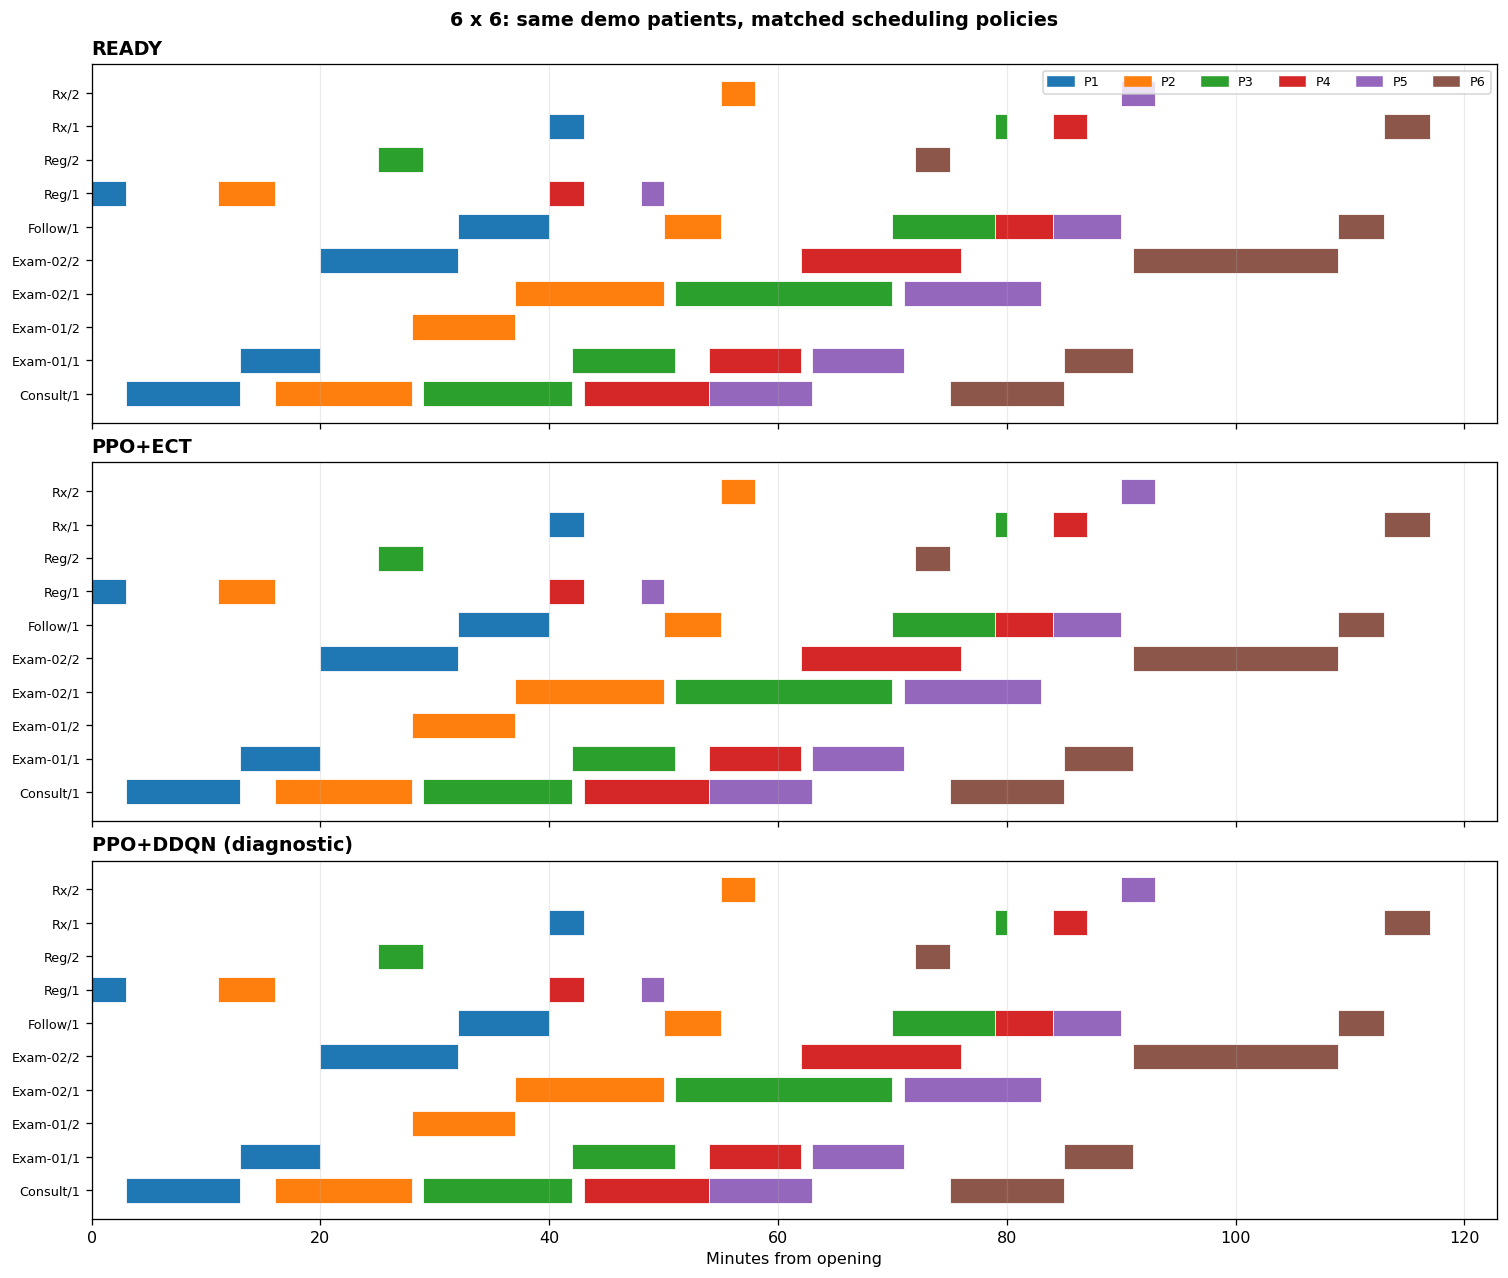

,feasible,total_flow,mean_flow,p90_wait
READY,True,501,50.1,12.3
PPO+ECT,True,490,49.0,12.0
PPO+DDQN（诊断）,True,490,49.0,12.0


,Task,Patient,Activity,Desk,Start (min),End (min)
0,0,1,Reg,Reg/2,0,2
1,1,1,Consult,Consult/1,2,9
2,3,1,Exam-02,Exam-02/1,9,13
3,2,1,Exam-01,Exam-01/2,13,29
4,6,2,Reg,Reg/1,18,19
5,7,2,Consult,Consult/1,19,31
6,12,3,Reg,Reg/1,24,26
7,4,1,Follow,Follow/1,29,37
8,18,4,Reg,Reg/1,30,32
9,13,3,Consult,Consult/1,31,44


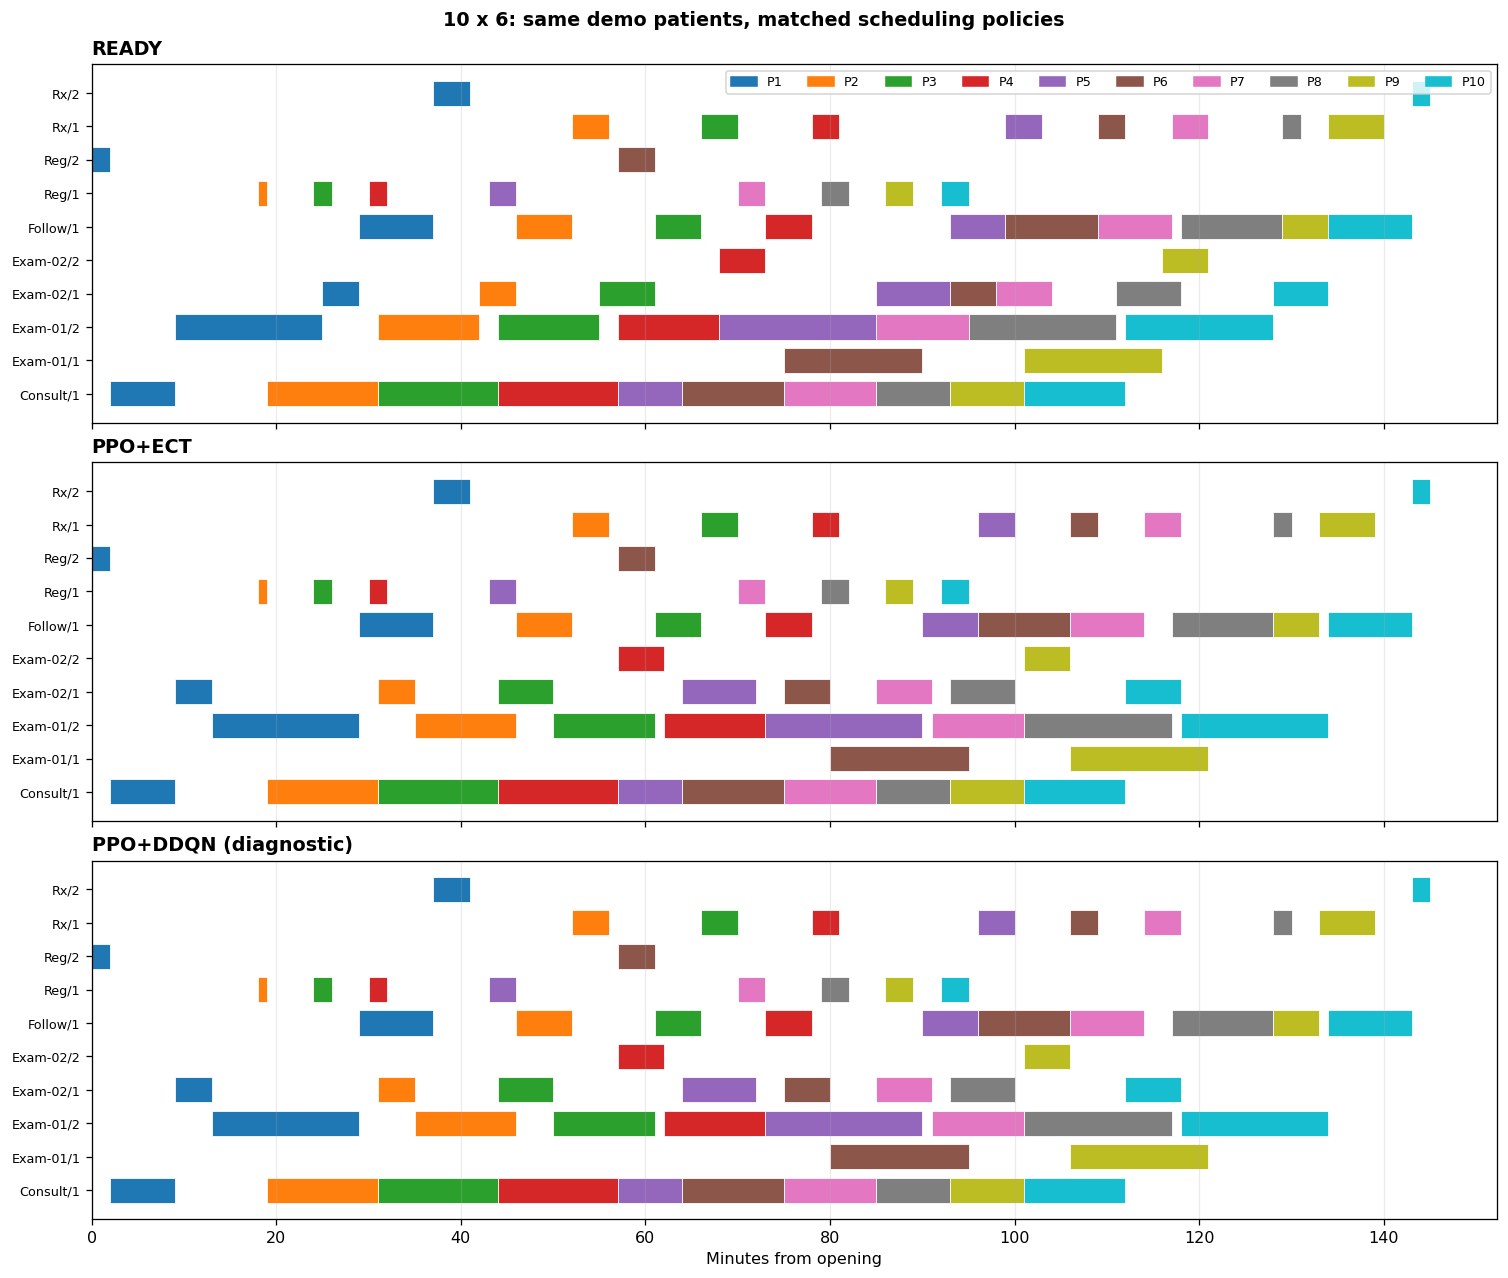

In [15]:
demo_replays = {}
for label in small_models:
    if label not in models:
        continue
    folder = RESULTS if label == "6x6" else RESULTS / label
    folder.mkdir(exist_ok=True)
    n, m = sizes[label]
    demo_seed = 5_209_001_001 + n - 6
    demo = synthetic(n, m, 2, demo_seed, "near_capacity")
    agent, desk_agent = models[label]
    print(f"{n}×{m} 排程示例")
    solutions = {"READY":rule(demo,"READY"), "PPO+ECT":fast_learned(demo,agent)}
    focus="PPO+ECT"
    if desk_agent is not None:
        focus="PPO+DDQN" if selection.set_index("model").loc[label,"ddqn_mode"]=="正式" else "PPO+DDQN（诊断）"
        solutions[focus]=fast_learned(demo,agent,desk_agent)
    display(pd.DataFrame({label:measures(demo,rows) for label,rows in solutions.items()}).T)
    for method, rows in solutions.items():
        schedule_frame(demo,rows).to_csv(folder/f"demo_{method}.csv",index=False)
    display(schedule_frame(demo,solutions[focus]).head(12))

    palette = plt.get_cmap("tab10")
    fig, axes = plt.subplots(len(solutions), 1, figsize=(13, 11), sharex=True, layout="constrained")
    desk_pos = {name: i for i, name in enumerate(demo.desks)}
    for ax, (method, rows) in zip(axes, solutions.items()):
        for b in rows:
            patient = demo.tasks[b.task].patient
            ax.barh(desk_pos[b.desk], b.end-b.start, left=b.start, height=.75,
                    color=palette(patient), edgecolor="white", linewidth=.5)
        ax.set_yticks(range(len(demo.desks)), demo.desks, fontsize=8)
        ax.set_title(method.replace("（诊断）", " (diagnostic)"), loc="left", fontweight="bold")
        ax.grid(axis="x", alpha=.25)
    axes[0].legend(handles=[Patch(color=palette(i), label=f"P{i+1}") for i in range(len(demo.case.arrival))],
                   loc="upper right", ncol=min(10, n), fontsize=8)
    axes[-1].set_xlabel("Minutes from opening")
    fig.suptitle(f"{n} x {m}: same demo patients, matched scheduling policies", fontweight="bold")
    fig.savefig(folder / "demo_gantt.png", dpi=160, bbox_inches="tight")
    display(fig)
    plt.close(fig)
    demo_replays[label] = demo, solutions[focus], folder


6x6 事件回放
10x6 事件回放
表格、图和逐单结果目录 hospital_latest_results/small_pilot_9fbeb7d9dd/report


,Minute,Arrived,In service,Waiting,Completed,Active bookings
0,0,1,1,0,0,P1@Reg/1
4,16,2,2,0,0,"P1@Exam-01/1, P2@Consult/1"
9,32,3,3,0,0,"P2@Exam-01/2, P3@Consult/1, P1@Follow/1"
14,48,5,4,0,1,"P2@Exam-02/1, P5@Reg/1, P4@Consult/1, P3@Exam-..."
19,58,5,3,0,2,"P3@Exam-02/1, P5@Consult/1, P4@Exam-01/1"
23,71,5,3,0,2,"P4@Exam-02/2, P5@Exam-02/1, P3@Follow/1"
28,80,6,3,0,3,"P6@Consult/1, P5@Exam-02/1, P4@Follow/1"
33,90,6,2,0,4,"P6@Exam-01/1, P5@Rx/2"
38,117,6,0,0,6,


,Minute,Arrived,In service,Waiting,Completed,Active bookings
0,0,1,1,0,0,P1@Reg/2
7,26,3,2,1,0,"P1@Exam-01/2, P2@Consult/1"
14,41,4,2,1,1,"P2@Exam-01/2, P3@Consult/1"
22,61,6,3,1,2,"P3@Follow/1, P4@Exam-02/2, P5@Consult/1"
29,75,7,4,0,3,"P4@Follow/1, P5@Exam-01/2, P6@Exam-02/1, P7@Co..."
36,86,9,5,0,4,"P5@Exam-01/2, P6@Exam-01/1, P7@Exam-02/1, P8@C..."
44,100,10,3,2,5,"P6@Follow/1, P7@Exam-01/2, P9@Consult/1"
51,118,10,3,0,7,"P8@Follow/1, P9@Exam-01/1, P10@Exam-01/2"
59,145,10,0,0,10,


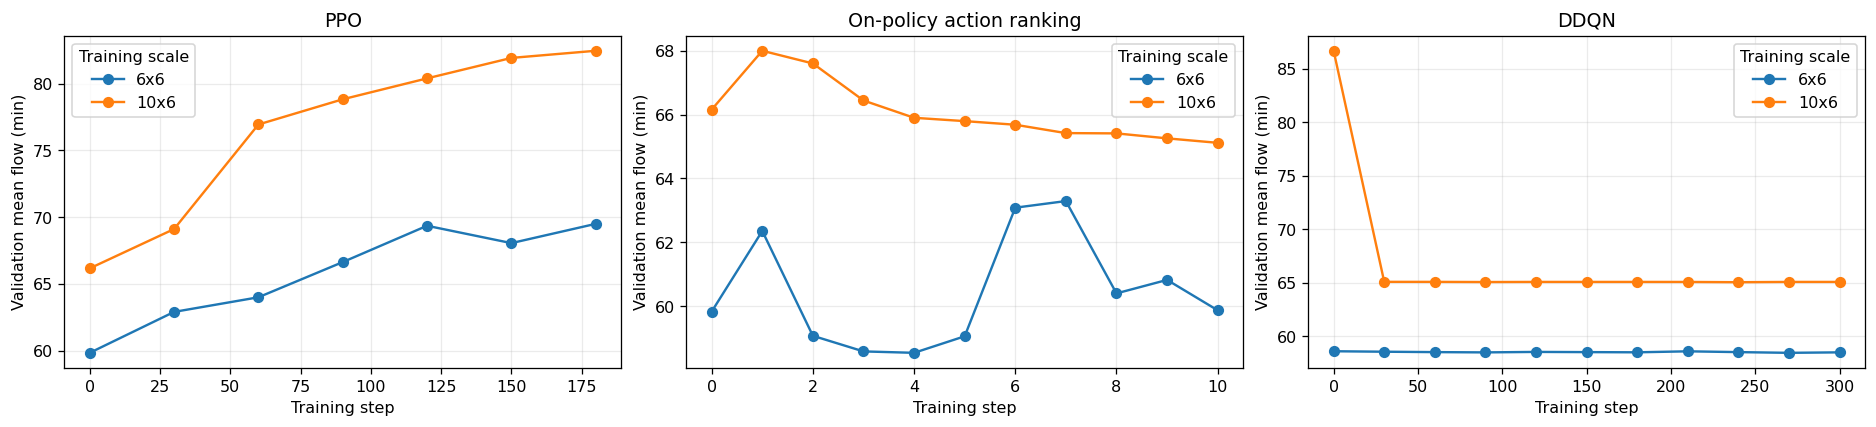

In [16]:
def replay_states(p, rows):
    finish = {i: max(b.end for b in rows if p.tasks[b.task].patient == i)
              for i in range(len(p.case.arrival))}
    times = sorted(set(p.case.arrival) | {b.start for b in rows} | {b.end for b in rows})
    timeline = []
    for t in times:
        arrived = sum(a <= t for a in p.case.arrival)
        busy = [b for b in rows if b.start <= t < b.end]
        done = sum(e <= t for e in finish.values())
        waiting = arrived-len(busy)-done
        assert waiting >= 0
        timeline.append((t, arrived, len(busy), waiting, done,
                         ", ".join(f"P{p.tasks[b.task].patient+1}@{b.desk}" for b in busy)))
    return pd.DataFrame(timeline, columns=["Minute", "Arrived", "In service", "Waiting",
                                           "Completed", "Active bookings"])

for label, (problem, rows, folder) in demo_replays.items():
    print(f"{label} 事件回放")
    timeline = replay_states(problem, rows)
    timeline.to_csv(folder / "demo_event_replay.csv", index=False)
    assert timeline.iloc[-1]["Completed"] == len(problem.case.arrival)
    display(timeline.iloc[np.unique(np.linspace(0, len(timeline)-1, 9).astype(int))])

stages=[name for name in ("PPO","自身排程排序","DDQN") if name in set(history.stage)]
fig,axes=plt.subplots(1,len(stages),figsize=(5.4*len(stages),3.6),layout="constrained",squeeze=False)
for ax,stage in zip(axes[0],stages):
    for label,rows in history[history.stage.eq(stage)].groupby("model",sort=False):
        ax.plot(rows.step,rows.validation_flow,"o-",label=label)
    ax.set(xlabel="Training step",ylabel="Validation mean flow (min)",
           title={"PPO":"PPO","自身排程排序":"On-policy action ranking","DDQN":"DDQN"}[stage])
    ax.grid(alpha=.25)
    ax.legend(title="Training scale")
fig.savefig(RESULTS/"validation_curves.png",dpi=150,bbox_inches="tight")
display(fig)
plt.close(fig)
print("表格、图和逐单结果目录",RESULTS)

## 12. 结果边界

- 运行结果是合成病例的实测。默认的性能结果覆盖 6×6 和 10×6。更大规模的评测入口为 `RUN_SCOPE="all"`。
- `DDQN 未启训` 表示本次 PPO 验证没有通过预设门槛。要研究分台可打开诊断开关，诊断结果和正式结果分别标记。
- 原文：[Discover Computing, DOI 10.1007/s10791-024-09474-1](https://doi.org/10.1007/s10791-024-09474-1)。


## 补充记录 · 双智能体诊断

两组 PPO 在验证集未达到 READY 门槛，正文仍分别完成 300 轮 DDQN 诊断训练，并将结果标为诊断。留出集覆盖 216 个场景，每个场景比较 8 种策略，共完成 1,728 次排程。三窗口结果在第 13 节按规模列出。


## 13. 门诊调度动态回放台

运行本节即可生成互动页面。默认打开 **10×6**，也可切到 **6×6**。默认展示每类检查 **3 个窗口**，可切换 1、2、3 个窗口。点击播放或拖动时间轴，再点击患者卡片、窗口里的患者或甘特图色块，查看这位患者每一步的等待、服务和离院时间。可逐事件前进、后退，或用相同的模拟时刻切换策略。比较表和个人轨迹会同步更新。

每个规模演示一批独立的合成患者。五种策略在同一规模内共用到达时间、活动需求及窗口条件。每个规模使用各自训练的 PPO 权重。正文默认打开 DDQN 诊断开关。两组 PPO 验证未过门槛时，DDQN 仍训练并以「诊断」单列。关闭该开关时，本节在独立目录生成演示权重。页面上的等待和在院时间是当前示例的结果。跨病例结果见第 10 节和诊断附录。

初诊和复诊各固定一个窗口。挂号、每类检查和取药各有 1、2 或 3 个候选窗口。DDQN 仅在候选窗口超过一个时做分台决策。三种窗口配置复用同一批患者及同一组到达时间。

时钟以模拟开诊 **09:00** 为零点。窗口候诊显示已经到达、完成前序服务并等待该排程所分配窗口的患者。页面播放算好的排程。Notebook 内嵌与导出的 HTML 使用同一份数据，浏览器可离线打开。


In [17]:
# 展示用病例与训练集、验证集和正式留出集分开。
# 原来的默认门槛照常生效。若正式结果没有 DDQN 权重，单独训练展示用诊断权重。
replay_models, replay_modes = {}, {}
mode_by_model = selection.set_index("model")["ddqn_mode"]
for model_label in small_models:
    if model_label not in models:
        continue
    replay_ppo, replay_ddqn = models[model_label]
    replay_mode = mode_by_model.loc[model_label]
    if replay_ddqn is None:
        experiment_out, experiment_diagnostic = OUT, RUN_DDQN_DIAGNOSTIC
        try:
            OUT = experiment_out / "replay_diagnostics"
            OUT.mkdir(exist_ok=True)
            RUN_DDQN_DIAGNOSTIC = True
            n, m = sizes[model_label]
            diagnostic_ppo, replay_ddqn, _, replay_fit = fit(
                model_label, n, m, seeds[model_label], PPO_ROUNDS, DDQN_EPISODES,
                VALIDATION_CASES, VALIDATE_EVERY, SAVE_EVERY, "window_aware"
            )
        finally:
            OUT, RUN_DDQN_DIAGNOSTIC = experiment_out, experiment_diagnostic
        assert all(np.array_equal(a, b) for a, b in zip(
            replay_ppo.parameters, diagnostic_ppo.parameters, strict=True
        )), "诊断应使用与正文相同的患者调度权重"
        assert replay_fit["ddqn_mode"] == "诊断"
        replay_mode = "诊断"
    assert replay_ddqn is not None
    replay_models[model_label] = (replay_ppo, replay_ddqn)
    replay_modes[model_label] = replay_mode

def encode_replay(problem, rows, elapsed_ms):
    errors = audit(problem, rows)
    assert not errors, errors
    by_task = {booking.task: booking for booking in rows}
    patients, events = [], []
    for index, arrival in enumerate(problem.case.arrival):
        patient_id = f"P{index+1:02d}"
        ready = arrival
        events.append(dict(t=arrival, type="arrival", patient=patient_id))
        steps = []
        for booking in sorted((by_task[i] for i in problem.by_patient[index]),
                              key=lambda b: b.start):
            activity = problem.tasks[booking.task].kind
            step = dict(activity=activity, desk=booking.desk, ready=ready,
                        start=booking.start, end=booking.end)
            assert ready <= booking.start < booking.end
            steps.append(step)
            fields = dict(patient=patient_id, activity=activity, desk=booking.desk)
            if ready < booking.start:
                events.append(dict(t=ready, type="queue", **fields))
            events.append(dict(t=booking.start, type="start", **fields))
            events.append(dict(t=booking.end, type="end", **fields))
            ready = booking.end
        flow = ready-arrival
        wait = sum(s["start"]-s["ready"] for s in steps)
        service = sum(s["end"]-s["start"] for s in steps)
        assert wait + service == flow
        patients.append(dict(id=patient_id, arrival=arrival, finish=ready,
                             flow=flow, wait=wait, service=service, steps=steps))
        events.append(dict(t=ready, type="departure", patient=patient_id))

    event_order = {event: i for i, event in enumerate(
        ("end", "departure", "arrival", "queue", "start")
    )}
    events.sort(key=lambda event: (event["t"], event_order[event["type"]], event["patient"]))
    stats = measures(problem, rows)
    assert stats["total_flow"] == sum(patient["flow"] for patient in patients)
    assert np.isclose(stats["p90_wait"], np.quantile([p["wait"] for p in patients], 0.9))
    metrics = dict(flow=stats["mean_flow"], wait=sum(p["wait"] for p in patients)/len(patients),
                   p90=stats["p90_wait"], ms=elapsed_ms, finish=max(p["finish"] for p in patients))

    # 核对导出的患者状态与原回放函数在每个事件时刻的统计。
    for minute, arrived, busy, waiting, completed, _ in replay_states(problem, rows).itertuples(index=False, name=None):
        current = [
            "future" if minute < p["arrival"] else "completed" if minute >= p["finish"]
            else "busy" if any(s["start"] <= minute < s["end"] for s in p["steps"])
            else "waiting"
            for p in patients
        ]
        assert arrived == len(patients) - current.count("future")
        assert (busy, waiting, completed) == tuple(current.count(s) for s in ("busy", "waiting", "completed"))
    return dict(patients=patients, events=events, metrics=metrics)

class AuditedDeskPolicy:
    """记录实际调用分台策略时的候选数，并检查输出是否合法。"""
    def __init__(self, model):
        self.model = model
        self.candidate_counts = []

    def choose(self, state):
        count = int(state[1])
        choice = int(self.model.choose(state))
        assert count > 1 and 0 <= choice < count
        self.candidate_counts.append(count)
        return choice

replay_cases, replay_summary = {}, []
for size, case_seed in ((6, 5_209_001_001), (10, 5_209_001_005)):
    model_label = f"{size}x6"
    if model_label not in replay_models:
        continue
    label = f"{size}×6"
    replay_ppo, replay_ddqn = replay_models[model_label]
    replay_dual_label = "PPO+DDQN（诊断）" if replay_modes[model_label] == "诊断" else "PPO+DDQN"
    variants = {}
    reference = synthetic(size, 6, 1, case_seed, "near_capacity")
    for windows in (1, 2, 3):
        problem = synthetic(size, 6, windows, case_seed, "near_capacity")
        assert problem.case.arrival == reference.case.arrival
        assert [(t.patient,t.kind,t.before,t.options[0]) for t in problem.tasks] == [
            (t.patient,t.kind,t.before,t.options[0]) for t in reference.tasks
        ]
        assert all(len(t.options) == (1 if t.kind in ("Consult", "Follow") else windows)
                   for t in problem.tasks)
        desk_policy = AuditedDeskPolicy(replay_ddqn)
        schedulers = {
            "READY": lambda: rule(problem, "READY"),
            "GA": lambda: genetic(problem, case_seed+77, GA_POPULATION, GA_GENERATIONS),
            "PPO+ECT": lambda: fast_learned(problem, replay_ppo),
            "PPO+DDQN": lambda: fast_learned(problem, replay_ppo, desk_policy),
        }
        plans = {}
        for method, schedule in schedulers.items():
            started = time.perf_counter_ns()
            bookings = schedule()
            elapsed_ms = (time.perf_counter_ns()-started)/1e6
            plan = encode_replay(problem, bookings, elapsed_ms)
            plans[method] = plan
            metrics = plan["metrics"]
            replay_summary.append({
                "规模": label, "检查窗口/类": windows,
                "策略": replay_dual_label if method == "PPO+DDQN" else method,
                "DDQN分台次数": len(desk_policy.candidate_counts) if method == "PPO+DDQN" else None,
                "活动数": problem.n, "事件数": len(plan["events"]),
                "平均等待（分钟/人）": metrics["wait"], "平均在院（分钟/人）": metrics["flow"],
                "P90等待（分钟）": metrics["p90"], "单次排程（毫秒）": metrics["ms"],
            })
        assert sorted(desk_policy.candidate_counts) == sorted(
            len(t.options) for t in problem.tasks if len(t.options) > 1
        )
        assert all([p["arrival"] for p in plan["patients"]] == list(problem.case.arrival)
                   for plan in plans.values())
        variants[windows] = dict(
            seed=case_seed, desks=problem.desks, plans=plans, dualLabel=replay_dual_label,
            ddqnDecisions=len(desk_policy.candidate_counts),
            finish=max(plan["metrics"]["finish"] for plan in plans.values())
        )
    replay_cases[label] = variants

replay_data = dict(cases=replay_cases)
replay_summary_frame = pd.DataFrame(replay_summary)
display(replay_summary_frame.round(3))
# 正文留出集按窗口数再拆一层，单独检验 3 窗口时 DDQN 的结果。
replay_grouped = raw[raw["method"].isin(
    ["READY", "GA", "PPO+ECT", "PPO+DDQN", "PPO+DDQN（诊断）"]
) & raw["patients"].isin([6, 10]) & raw["activities"].eq(6)]
display(replay_grouped.pivot_table(index=["patients", "windows"], columns="method",
                                values="mean_flow").round(3))
print(f"回放验收通过：{len(replay_cases)} 个规模、{len(replay_summary)} 份排程。"
      "患者和窗口状态已逐事件核对，DDQN 的分台次数与多窗口活动数完全一致。")


回放验收通过：2 个规模、24 份排程。患者和窗口状态已逐事件核对，DDQN 的分台次数与多窗口活动数完全一致。


,规模,检查窗口/类,策略,DDQN分台次数,活动数,事件数,平均等待（分钟/人）,平均在院（分钟/人）,P90等待（分钟）,单次排程（毫秒）
0,6×6,1,READY,NaN,36,88,6.500,54.833,15.5,0.154
1,6×6,1,GA,NaN,36,87,5.500,53.833,14.5,28.568
2,6×6,1,PPO+ECT,NaN,36,88,6.500,54.833,15.5,2.600
3,6×6,1,PPO+DDQN（诊断）,0.0,36,88,6.500,54.833,15.5,2.423
4,6×6,2,READY,NaN,36,87,1.333,47.000,4.0,0.144
5,6×6,2,GA,NaN,36,87,1.333,47.000,4.0,25.706
6,6×6,2,PPO+ECT,NaN,36,87,1.333,47.000,4.0,2.613
7,6×6,2,PPO+DDQN（诊断）,24.0,36,87,1.333,47.000,4.0,3.326
8,6×6,3,READY,NaN,36,87,1.667,46.167,5.0,0.149
9,6×6,3,GA,NaN,36,87,1.667,46.167,5.0,26.175


method                GA  PPO+DDQN（诊断）  PPO+ECT   READY
patients windows                                       
6        1        72.819        76.042   76.042  76.694
         2        57.481        58.370   58.366  57.940
         3        54.139        54.958   54.986  54.546
10       1        76.300        80.442   80.442  79.897
         2        57.125        57.661   57.700  57.367
         3        54.786        55.292   55.253  54.872

In [18]:
replay_template = r"""
<!doctype html>
<html lang="zh-CN">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>门诊调度回放台</title>
<style>
:root{color-scheme:light;--ink:#15302e;--muted:#5b6c68;--line:#dbe3dc;--paper:#fff;--base:#f3f6f1;--forest:#123d34;--green:#186b52;--mint:#d9efe5;--warm:#fff0d9;--amber:#8a5114;--radius:15px;--shadow:0 3px 12px #244a3110}
*{box-sizing:border-box}
body{margin:0;background:var(--base);color:var(--ink);font:14px/1.55 system-ui,"Microsoft YaHei","PingFang SC",sans-serif}
button,input,select{font:inherit}
button,select{cursor:pointer}
button:focus-visible,select:focus-visible,input:focus-visible{outline:3px solid #1a875d;outline-offset:3px}
button:disabled{cursor:default;opacity:.45}
.wrap{max-width:1390px;margin:auto;padding:22px 24px 32px}
.hero{background:var(--forest);color:#f7fbf5;padding:24px 26px;border-radius:19px;display:flex;align-items:center;justify-content:space-between;gap:18px}
.eyebrow{color:#b7e5d2;font-size:12px;letter-spacing:.12em;margin:0 0 4px;font-weight:750}
h1{font-size:clamp(26px,4vw,38px);margin:0;font-weight:770;line-height:1.18}
.hero p:last-child{color:#d2e8dc;margin:8px 0 0}
.hero-tag{font-size:12px;border:1px solid #76a597;border-radius:20px;padding:5px 12px;white-space:nowrap;color:#e2f6eb}
.card{background:var(--paper);border:1px solid var(--line);border-radius:var(--radius);padding:16px 18px;box-shadow:var(--shadow);min-width:0}
.controls{margin-top:14px}
.select-row,.control-row,.header-row,.clock-row{display:flex;flex-wrap:wrap;gap:10px;align-items:center}
.select-row{gap:12px;justify-content:space-between;margin-bottom:12px}
.select-group{display:flex;flex-wrap:wrap;gap:10px}
.field{display:flex;gap:7px;align-items:center;color:var(--muted);font-weight:650}
select{border:1px solid #bdcfc3;background:white;color:var(--ink);border-radius:8px;padding:7px 9px;max-width:100%}
.hint{color:var(--muted);font-size:12px;margin:0}
.control-row{gap:7px}
.ctrl{border:1px solid #c2d3ca;background:#fff;color:var(--ink);border-radius:8px;padding:7px 10px;font-weight:660}
.ctrl.primary{background:var(--green);color:white;border-color:var(--green);min-width:70px}
.clock-row{margin-left:auto;gap:9px;color:var(--muted)}
#clock{font:750 28px/1.15 ui-monospace,monospace;color:var(--forest);font-variant-numeric:tabular-nums}
.seek-row{display:flex;gap:10px;align-items:center;margin-top:8px;color:var(--muted);font-size:12px;font-variant-numeric:tabular-nums}
#seek{flex:1;min-width:60px;accent-color:var(--green)}
#next-event{padding-top:4px;min-height:22px}
.stats{display:grid;grid-template-columns:repeat(4,minmax(0,1fr));gap:10px;margin:14px 0}
.stat{padding:10px 15px;background:#fff;border:1px solid var(--line);border-radius:11px}
.stat strong{display:block;font:760 24px/1.2 ui-monospace,monospace;font-variant-numeric:tabular-nums}
.stat span{color:var(--muted);font-size:12px}
.stat.wait{background:var(--warm);border-color:#ecd9ba}
.stat.busy{background:#e7f2ec}
.main-grid{display:grid;grid-template-columns:minmax(0,1.35fr) minmax(0,1fr);gap:12px;align-items:start}
.stack{display:grid;gap:12px;min-width:0}
.header-row{justify-content:space-between;margin-bottom:9px}
h2{font-size:18px;margin:0;line-height:1.3}
h3{font-size:14px;margin:0}
.patient-grid{display:grid;grid-template-columns:repeat(5,minmax(0,1fr));gap:7px}
.patient,.person-link{color:var(--ink);background:var(--pc,#edf4ef);border:1px solid #acbdb5;border-radius:8px}
.patient{padding:7px 5px;text-align:left;min-width:0}
.patient b,.patient small{display:block;overflow:hidden;text-overflow:ellipsis;white-space:nowrap}
.patient small{color:#3f554e;font-size:11px}
.patient[aria-pressed=true]{box-shadow:inset 0 0 0 2px #1a664f;border-color:#1a664f}
.person-link{font-weight:700;font-size:12px;padding:1px 5px}
.windows{display:grid;grid-template-columns:repeat(3,minmax(0,1fr));gap:7px}
.desk{border:1px solid var(--line);border-radius:9px;padding:8px;min-width:0;background:#fafcf9}
.desk.active{background:#edf8f2;border-color:#b9daca}
.desk-title{display:flex;flex-wrap:wrap;gap:3px 6px;justify-content:space-between;align-items:center;font-weight:750}
.desk-current,.desk-queue{color:var(--muted);font-size:12px;margin-top:4px;min-height:19px;overflow-wrap:anywhere}
.desk-queue button{margin:0 2px 2px 0}
.badge{color:var(--green);background:var(--mint);border-radius:12px;padding:2px 7px;font-size:11px;font-weight:700;white-space:nowrap}
.badge.wait{background:var(--warm);color:var(--amber)}
.badge.off{background:#edf1ed;color:#617069}
.patient-info{display:flex;flex-wrap:wrap;gap:7px 14px;color:var(--muted);margin:0 0 8px;font-size:12px}
.patient-info b{color:var(--ink)}
.table-box{overflow:auto}
table{border-collapse:collapse;width:100%;font-size:12px;font-variant-numeric:tabular-nums}
th,td{text-align:left;white-space:nowrap;padding:7px 6px;border-bottom:1px solid #e5eae4}
th{color:var(--muted);font-weight:730;background:#f7faf6}
tr.now{background:#e9f7ee}
tr.plan{color:var(--muted)}
tr.chosen{background:#e8f5ed;font-weight:700}
tr.baseline td:first-child{border-left:3px solid #d5a45c}
td.num,th.num{text-align:right}
.event-options{font-size:12px;color:var(--muted)}
.event-list{list-style:none;padding:0;margin:0;max-height:264px;overflow:auto}
.event-list li{display:grid;grid-template-columns:43px 48px minmax(0,1fr);gap:6px;align-items:start;padding:5px 1px;border-bottom:1px solid #e8ede7}
.event-list li.empty{display:block;color:var(--muted)}
.time-link{background:transparent;border:0;color:var(--green);font:700 12px ui-monospace,monospace;padding:4px 0;text-align:left}
.event-list li.current{background:#edf7ee}
.event-list li span{padding-top:1px}
.wide{margin-top:12px}
.gantt-scroll{overflow:auto;padding-top:5px}
.gantt-grid{display:grid;grid-template-columns:126px minmax(660px,1fr);min-width:790px;align-items:stretch}
.gantt-label{height:28px;display:flex;align-items:center;border-bottom:1px solid #e7ece6;color:var(--muted);font-size:12px}
.gantt-body{position:relative}
.lane{height:28px;position:relative;border-bottom:1px solid #e7ece6;background:linear-gradient(to right,#e6ede6 1px,transparent 1px) left top/var(--tick-step) 100%}
.gantt-task{position:absolute;height:19px;top:4px;border:1px solid #58786b;border-radius:4px;min-width:3px;padding:0;background:var(--pc);color:#183931;font-size:10px;font-weight:740;white-space:nowrap;overflow:hidden}
.gantt-task.other{opacity:.65}
.gantt-task.selected{z-index:1;border:2px solid #123d34}
.gantt-task:focus-visible{z-index:5}
.playhead{pointer-events:none;position:absolute;top:0;bottom:0;width:2px;background:#b45120;z-index:2}
.gantt-axis{height:23px;position:relative}
.gantt-axis span{font:11px ui-monospace,monospace;color:var(--muted);position:absolute;transform:translateX(-35%);top:5px;white-space:nowrap}
.metric-note{margin-top:6px}
footer{color:var(--muted);font-size:12px;margin-top:15px}
@media(max-width:1020px){.windows{grid-template-columns:repeat(2,minmax(0,1fr))}.patient-grid{grid-template-columns:repeat(4,minmax(0,1fr))}}
@media(max-width:760px){.wrap{padding:10px 10px 22px}.hero{padding:17px;align-items:flex-start;flex-direction:column;gap:10px}.main-grid{grid-template-columns:1fr}.select-row{gap:7px}.stats{gap:6px}.stat{padding:8px}.clock-row{margin-left:0}.card{padding:12px}}
@media(max-width:420px){.field{flex-direction:column;align-items:flex-start;gap:2px}.patient-grid{grid-template-columns:repeat(3,minmax(0,1fr))}.stat strong{font-size:20px}}
</style>
</head>
<body>
<div class="wrap" id="app">
<header class="hero">
<div><p class="eyebrow">门诊多窗口调度仿真</p><h1>门诊调度回放台</h1>
<p>沿着同一批患者的时间线，查看候诊、分台和离院。</p></div>
<div class="hero-tag">合成病例 · 离线演示</div>
</header>
<section class="card controls" aria-label="回放控制">
  <div class="select-row">
    <div class="select-group">
      <label class="field">病例规模 <select id="case"></select></label>
      <label class="field">每类检查窗口 <select id="window-count"><option value="1">1 个</option><option value="2">2 个</option><option value="3" selected>3 个</option></select></label>
      <label class="field">回放策略 <select id="method"></select></label>
      <label class="field">对照策略 <select id="baseline"></select></label>
    </div>
    <p class="hint" id="case-note"></p>
  </div>
  <div class="control-row">
    <button type="button" class="ctrl primary" id="play">播放</button>
    <button type="button" class="ctrl" id="previous">上一事件</button>
    <button type="button" class="ctrl" id="next">下一事件</button>
    <button type="button" class="ctrl" id="reset">回到开诊</button>
    <label class="field">倍速 <select id="speed"><option value="1">1×</option><option value="2">2×</option><option value="4">4×</option></select></label>
    <div class="clock-row"><span>模拟时钟</span><strong id="clock">09:00</strong></div>
  </div>
  <div class="seek-row"><span>09:00</span><input id="seek" aria-label="模拟时刻" type="range" min="0" step="1"><span id="end-time"></span></div>
  <p id="next-event" class="hint"></p>
</section>
<section class="stats" aria-label="患者状态统计">
  <div class="stat"><strong id="arrived">0</strong><span>累计到达</span></div>
  <div class="stat wait"><strong id="waiting">0</strong><span>正在候诊</span></div>
  <div class="stat busy"><strong id="busy">0</strong><span>正在服务</span></div>
  <div class="stat"><strong id="completed">0</strong><span>已离院</span></div>
</section>
<div class="main-grid">
<div class="stack">
<section class="card">
<div class="header-row"><h2>患者列表</h2><p class="hint">点击查看完整轨迹</p></div>
<div id="patient-list" class="patient-grid"></div>
</section>
<section class="card">
<div class="header-row"><h2>窗口状态</h2><p class="hint">候诊按该策略已分配的窗口统计</p></div>
<div id="windows" class="windows"></div>
</section>
</div>
<div class="stack">
<section class="card">
<div class="header-row"><h2 id="patient-title">患者轨迹</h2><span class="badge" id="patient-status"></span></div>
<p id="patient-info" class="patient-info"></p>
<div class="table-box"><table aria-label="患者活动时间线"><thead><tr><th>活动</th><th>窗口</th><th>就绪</th><th>开始–结束</th><th class="num">等待</th><th class="num">服务</th></tr></thead><tbody id="patient-steps"></tbody></table></div>
<p id="patient-compare" class="hint metric-note"></p>
</section>
<section class="card">
<div class="header-row"><h2>事件回放</h2><label class="event-options"><input id="filter-patient" type="checkbox"> 只看所选患者</label></div>
<ul id="events" class="event-list" aria-label="截至当前时刻的事件"></ul>
</section>
</div>
</div>
<section class="card wide">
<div class="header-row"><h2>窗口甘特图</h2><p class="hint">色块代表服务时段，竖线标记当前时刻。点击色块选中患者。</p></div>
<div id="gantt" class="gantt-scroll"></div>
</section>
<section class="card wide">
<div class="header-row"><h2>同一批患者的策略对照</h2><p class="hint" id="comparison-note"></p></div>
<div class="table-box"><table aria-label="策略对照"><thead><tr><th>策略</th><th class="num">平均等待（分/人）</th><th class="num">平均在院（分/人）</th><th class="num">P90 等待（分）</th><th class="num">排程（毫秒）</th></tr></thead><tbody id="comparison"></tbody></table></div>
<p class="hint metric-note">P90 表示约九成患者的累计等待时间在这个数值以内。排程耗时是这一个病例的一次计算时间。</p>
</section>
<footer>回放使用离线仿真排程。跨病例结论以 Notebook 的留出集评测为准。</footer>
</div>
<script id="replay-data" type="application/json">__REPLAY_PAYLOAD__</script>
<script>
"use strict";
const data = JSON.parse(document.getElementById("replay-data").textContent);
const cases = data.cases;
const $ = id => document.getElementById(id);
const state = {scenario: cases["10×6"] ? "10×6" : Object.keys(cases)[0],
  windows:3, method:"READY", baseline:"READY", patient:"P01", minute:0, timer:null};
const colors = ["#bfe1d1","#ffdbb6","#c8daf9","#e0c8f2","#f4ccc7",
  "#f0e1a8","#c7e4a9","#c7e8e8","#d5d7f6","#ecd3ae"];
const activities = {Reg:"挂号", Consult:"初诊", Follow:"回诊", Rx:"取药"};
const statusLabels = {future:"未到达", waiting:"候诊", busy:"服务中", completed:"已离院"};
const eventLabels = {arrival:"到达",queue:"开始等候",start:"开始服务",end:"完成服务",departure:"离院"};
const scenario = () => cases[state.scenario][state.windows];
const plan = () => scenario().plans[state.method];
const methodName = key => key === "PPO+DDQN" ? scenario().dualLabel : key;
const color = id => colors[(Number(id.slice(1))-1) % colors.length];
const activityName = key => activities[key] || key.replace("Exam-", "检查 ");
function deskName(key) {
  const [kind, index] = key.split("/");
  return activityName(kind) + " " + index + " 号窗";
}
function timeText(minute) {
  const total = 540 + minute;
  return [Math.floor(total/60), total%60].map(v => String(v).padStart(2,"0")).join(":");
}
function patientState(patient, minute) {
  if (minute < patient.arrival) return {type:"future"};
  if (minute >= patient.finish) return {type:"completed"};
  const step = patient.steps.find(s => minute < s.end);
  return {type:minute < step.start ? "waiting" : "busy", step};
}
function personButton(id) {
  return `<button type="button" class="person-link" data-patient="${id}" style="--pc:${color(id)}">${id}</button>`;
}
function badgeClass(type) { return type === "waiting" ? " wait" : (type === "future" ? " off" : ""); }
function renderPatients(live) {
  $("patient-list").innerHTML = live.map(({patient:p, current:s}) =>
    `<button type="button" class="patient" data-patient="${p.id}" style="--pc:${color(p.id)}" aria-pressed="${p.id === state.patient}">
    <b>${p.id}</b><small>${statusLabels[s.type]}${s.step ? " · "+activityName(s.step.activity) : ""}</small></button>`).join("");
}
function renderWindows(live) {
  const byDesk = new Map(scenario().desks.map(key => [key, {busy:null, queue:[]}]));
  for (const {patient, current} of live) {
    if (!current.step) continue;
    const desk = byDesk.get(current.step.desk);
    if (current.type === "busy") desk.busy = patient.id;
    else desk.queue.push({id:patient.id, ready:current.step.ready});
  }
  $("windows").innerHTML = Array.from(byDesk, ([desk, status]) => {
    const queue = status.queue.sort((a,b) => a.ready-b.ready || a.id.localeCompare(b.id));
    return `<article class="desk ${status.busy ? "active" : ""}" data-desk="${desk}">
      <div class="desk-title">${deskName(desk)} <span class="badge ${status.busy ? "" : "off"}">${status.busy ? "服务中" : "空闲"}</span></div>
      <div class="desk-current">${status.busy ? "当前 "+personButton(status.busy) : "当前 · —"}</div>
      <div class="desk-queue">候诊 ${queue.length} 人 ${queue.map(x => personButton(x.id)).join("")}</div>
      </article>`;
  }).join("");
}
function signed(value) { return value > 0 ? "+" + value : String(value); }
function renderPatient(live) {
  const {patient:p, current:s} = live.find(x => x.patient.id === state.patient);
  const base = scenario().plans[state.baseline].patients.find(x => x.id === p.id);
  $("patient-title").textContent = p.id + " 患者轨迹";
  $("patient-status").textContent = statusLabels[s.type];
  $("patient-status").className = "badge" + badgeClass(s.type);
  $("patient-info").innerHTML =
    `<span>到达 <b>${timeText(p.arrival)}</b></span><span>离院 <b>${timeText(p.finish)}</b></span>
    <span>累计等待 <b>${p.wait} 分</b></span><span>在院 <b>${p.flow} 分</b></span>`;
  $("patient-steps").innerHTML = p.steps.map(step => {
    const row = state.minute >= step.ready && state.minute < step.end ? "now" : (state.minute < step.ready ? "plan" : "");
    return `<tr class="${row}"><td>${activityName(step.activity)}</td><td>${deskName(step.desk)}</td><td>${timeText(step.ready)}</td>
      <td>${timeText(step.start)}–${timeText(step.end)}</td><td class="num">${step.start-step.ready} 分</td><td class="num">${step.end-step.start} 分</td></tr>`;
  }).join("");
  $("patient-compare").textContent = `与 ${methodName(state.baseline)} 相比，这位患者等待 ${signed(p.wait-base.wait)} 分钟，在院 ${signed(p.flow-base.flow)} 分钟。`;
}
function eventText(event) {
  return eventLabels[event.type] + (event.desk ? " · " + deskName(event.desk) : "");
}
function renderEvents() {
  const events = plan().events;
  const next = events.find(event => event.t > state.minute);
  $("next-event").textContent = next ? `下一事件 ${timeText(next.t)} · ${next.patient} ${eventText(next)}` : "当前策略的全部事件已播放";
  const filtered = events.filter(e => e.t <= state.minute && (!$("filter-patient").checked || e.patient === state.patient));
  $("events").innerHTML = filtered.slice(-30).reverse().map(event =>
    `<li class="${event.t === state.minute ? "current" : ""}"><button type="button" class="time-link" data-minute="${event.t}">${timeText(event.t)}</button>
     ${personButton(event.patient)}<span>${eventText(event)}</span></li>`).join("") ||
    '<li class="empty">这个时刻还没有可显示的事件。</li>';
}
function renderGantt() {
  const end = scenario().finish;
  const tick = end > 135 ? 30 : 20;
  const step = tick/end*100;
  const lanes = new Map(scenario().desks.map(d => [d, []]));
  for (const p of plan().patients) for (const s of p.steps) lanes.get(s.desk).push({p,s});
  const labels = Array.from(lanes.keys(), d => `<div class="gantt-label">${deskName(d)}</div>`).join("");
  const slots = Array.from(lanes.values(), bookings => `<div class="lane">${bookings.map(({p,s}) =>
    `<button type="button" class="gantt-task ${p.id === state.patient ? "selected" : "other"}" data-patient="${p.id}"
      style="left:${s.start/end*100}%;width:${(s.end-s.start)/end*100}%;--pc:${color(p.id)}"
      title="${p.id} · ${deskName(s.desk)} · ${timeText(s.start)}–${timeText(s.end)}">${p.id}</button>`).join("")}</div>`).join("");
  const ticks = Array.from({length:Math.floor(end/tick)+1}, (_,i) =>
    `<span style="left:${i*tick/end*100}%">${timeText(i*tick)}</span>`).join("");
  $("gantt").innerHTML = `<div class="gantt-grid"><div>${labels}</div><div class="gantt-body" style="--tick-step:${step}%">
    ${slots}<div id="playhead" class="playhead"></div><div class="gantt-axis">${ticks}</div></div></div>`;
}
function renderComparison() {
  const c = scenario();
  const desks = c.ddqnDecisions
    ? " · DDQN 分台 " + c.ddqnDecisions + " 次"
    : " · 单窗口，无分台选择";
  $("comparison-note").textContent = "当前回放 · " + methodName(state.method)
    + "　对照 · " + methodName(state.baseline) + desks;
  $("comparison").innerHTML = Object.entries(scenario().plans).map(([key,{metrics:m}]) =>
    `<tr class="${key === state.method ? "chosen " : ""}${key === state.baseline ? "baseline" : ""}">
      <td>${methodName(key)}</td><td class="num">${m.wait.toFixed(2)}</td><td class="num">${m.flow.toFixed(2)}</td>
      <td class="num">${m.p90.toFixed(2)}</td><td class="num">${m.ms.toFixed(2)}</td></tr>`).join("");
}
function renderMinute() {
  const live = plan().patients.map(patient => ({patient,current:patientState(patient,state.minute)}));
  const count = key => live.filter(({current}) => current.type === key).length;
  $("arrived").textContent = live.length-count("future");
  for (const key of ["waiting","busy","completed"]) $(key).textContent = count(key);
  $("clock").textContent = timeText(state.minute);
  $("seek").value = state.minute;
  $("seek").setAttribute("aria-valuetext", timeText(state.minute));
  $("playhead").style.left = Math.min(99.9, 100*state.minute/scenario().finish) + "%";
  const events = plan().events;
  $("previous").disabled = !events.some(e => e.t < state.minute);
  $("next").disabled = !events.some(e => e.t > state.minute);
  renderPatients(live);
  renderWindows(live);
  renderPatient(live);
  renderEvents();
}
function fillOptions(select, values, labelFor, active) {
  select.replaceChildren(...values.map(key => new Option(labelFor(key),key,false,key === active)));
}
function renderScenario() {
  const methods = Object.keys(scenario().plans);
  fillOptions($("method"), methods, methodName, state.method);
  fillOptions($("baseline"), methods, methodName, state.baseline);
  $("seek").max = scenario().finish;
  $("end-time").textContent = timeText(scenario().finish);
  $("case-note").textContent = state.scenario + " · 近满载 · 初诊和复诊各 1 个窗口";
  renderGantt();
  renderComparison();
  renderMinute();
}
function pause() {
  clearInterval(state.timer);
  state.timer = null;
  $("play").textContent = "播放";
}
function seek(minute) {
  state.minute = Math.max(0, Math.min(minute, scenario().finish));
  renderMinute();
}
function play() {
  if (state.minute >= scenario().finish) seek(0);
  $("play").textContent = "暂停";
  state.timer = setInterval(() => {
    seek(state.minute + 1);
    if (state.minute >= scenario().finish) pause();
  }, 220/Number($("speed").value));
}
function jumpEvent(direction) {
  pause();
  const times = plan().events.map(e => e.t);
  if (direction === -1) times.reverse();
  const minute = times.find(t => direction*(t-state.minute) > 0);
  if (minute !== undefined) seek(minute);
}

fillOptions($("case"), Object.keys(cases), key => key+"（"+key.split("×")[0]+" 人）", state.scenario);
$("case").addEventListener("change", () => {
  pause();
  state.scenario = $("case").value;
  state.minute = 0;
  if (!plan().patients.some(p => p.id === state.patient)) state.patient = "P01";
  renderScenario();
});
$("window-count").addEventListener("change", () => {
  pause();
  state.windows = Number($("window-count").value);
  state.minute = Math.min(state.minute, scenario().finish);
  renderScenario();
});
$("method").addEventListener("change", () => {
  state.method = $("method").value;
  renderGantt();
  renderComparison();
  renderMinute();
});
$("baseline").addEventListener("change", () => {
  state.baseline = $("baseline").value;
  renderComparison();
  renderMinute();
});
$("play").addEventListener("click", () => state.timer === null ? play() : pause());
$("previous").addEventListener("click", () => jumpEvent(-1));
$("next").addEventListener("click", () => jumpEvent(1));
$("reset").addEventListener("click", () => { pause(); seek(0); });
$("speed").addEventListener("change", () => { if (state.timer !== null) { pause(); play(); } });
$("seek").addEventListener("input", () => { pause(); seek(Number($("seek").value)); });
$("filter-patient").addEventListener("change", renderEvents);
$("app").addEventListener("click", event => {
  const btn = event.target.closest("button[data-patient],button[data-minute]");
  if (!btn) return;
  if (btn.dataset.patient) {
    state.patient = btn.dataset.patient;
    renderGantt();
    renderMinute();
    const selected = $("patient-list").querySelector("[aria-pressed=true]");
    if (selected) selected.focus({preventScroll:true});
  } else {
    pause();
    seek(Number(btn.dataset.minute));
  }
});
renderScenario();
</script>
</body>
</html>

"""

from html import escape
from urllib.parse import quote

payload = json.dumps(replay_data, ensure_ascii=False, allow_nan=False, separators=(",", ":"))
# 禁止 JSON 文本中的尖括号结束脚本数据标签。
payload = payload.replace("<", "\\u003c").replace(">", "\\u003e").replace("&", "\\u0026")
assert replay_template.count("__REPLAY_PAYLOAD__") == 1
replay_page = replay_template.replace("__REPLAY_PAYLOAD__", payload)
replay_html_path = RESULTS / "outpatient_replay.html"
replay_html_path.write_text(replay_page, encoding="utf-8")
print("互动回放页面已导出", replay_html_path)

class OutpatientReplay:
    def _repr_html_(self):
        source_url = quote(replay_html_path.as_posix())
        return (
            f'<p><a href="{source_url}" target="_blank" rel="noopener">单独打开门诊调度回放台</a></p>'
            f'<iframe title="门诊调度动态回放台" sandbox="allow-scripts" '
            f'style="width:100%;height:920px;border:1px solid #dbe3dc;border-radius:12px" '
            f'srcdoc="{escape(replay_page, quote=True)}"></iframe>'
        )

    def __repr__(self):
        return f"门诊调度动态回放台 · {replay_html_path}"

display(OutpatientReplay())


互动回放页面已导出 hospital_latest_results/small_pilot_9fbeb7d9dd/report/outpatient_replay.html


门诊调度动态回放台 · hospital_latest_results/small_pilot_9fbeb7d9dd/report/outpatient_replay.html